<center style="padding: 1em 2em; margin: 1em 0;">
<h1 style="font-size: 2.2em; margin: 0; color: rgb(52, 72, 92);">«Визуализация: от столбца до интерактивной карты»</h1>
</center>

Эта пара – **обзор возможностей и подходов к визуализации данных**. Разберём, какие бывают графики, на какие вопросы они отвечают и как выбирать подходящий способ представления. Для каждого примера обсудим, как читать результат и где можно ошибиться в его интерпретации.

На знакомой выборке поездок такси пройдём от простых столбцов к распределениям, связям и временным рядам, затем к интерактивным графикам, 3D и картам. Базовые приёмы разберём по шагам; более сложные примеры покажут возможности разных инструментов.

Прежде всего познакомимся с типами графиков. Разберём, на какие вопросы отвечает каждый из них и как менять представление под задачу.

<div>
<a href="../../Other/images/06_chart_types.png"><img src="../../Other/images/06_chart_types.png" width="1100" style="max-width: 100%; height: auto;" alt="Основные типы графиков: столбцы, круг, линия, гистограмма, коробка, точки, тепловая карта и полярный график"></a>
</div>

В примеры можно подставлять свои данные, адаптировать расчёты и экспериментировать с графиками. **Заучивать вызовы и параметры не нужно.** Важно уметь построить полезный график под свой вопрос, понимать его применимость и ограничения. Синтаксис и настройки всегда можно уточнить в документации: ссылки есть по ходу урока и в конце.

In [ ]:
# Установка необходимых пакетов
# !pip install numpy pandas matplotlib seaborn plotly geopandas folium networkx

## **От вопроса к графику.**

**Каких поездок больше: на жёлтом или на зелёном такси?** Для ответа достаточно двух чисел. Посчитаем строки каждой группы, а затем изобразим количества длинами столбцов.

Это та же [выборка taxis из `Seaborn`](https://github.com/mwaskom/seaborn-data/blob/master/taxis.csv), что в прошлой паре: одна строка соответствует поездке. Это учебная выборка, а не все поездки Нью-Йорка.

`color` обозначает тип такси, `pickup_borough` – крупный район отправления, `pickup_zone` – более мелкую зону. `distance` измеряется в милях, `fare` – базовая стоимость в долларах, `total` – итоговая сумма с дополнительными компонентами. Как в пятой паре, передадим адрес `CSV` прямо в `pd.read_csv`. Для чтения понадобится интернет; сначала работаем только с таблицей поездок.

In [1]:
import pandas as pd

url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/taxis.csv"
taxi = pd.read_csv(url)
taxi[["color", "pickup_borough", "distance", "fare"]].head(5)

,color,pickup_borough,distance,fare
0,yellow,Manhattan,1.60,7.0
1,yellow,Manhattan,0.79,5.0
2,yellow,Manhattan,1.37,7.5
3,yellow,Manhattan,7.70,27.0
4,yellow,Manhattan,2.16,9.0


### **Какие данные мы изображаем?**

Один столбец описывает один **признак** поездки. Тип данных помогает выбрать вопрос и график.

| Данные | Столбцы | Что сравниваем |
| --- | --- | --- |
| Категории | `color`, `payment`, `pickup_borough` | Количества и доли групп |
| Числа | `distance`, `fare`, `total`, `passengers` | Разброс и связь величин |
| Время | `pickup`, `dropoff` | Изменения и повторяющиеся ритмы |
| География | `pickup_zone` и справочник границ | Расположение зон |
| Связи | `pickup_borough`, `dropoff_borough` | Потоки между районами |

Начнём с одного признака, затем добавим группы и связи нескольких величин. Один столбец может участвовать в разных задачах: час посадки позволяет сравнить количества по часам, а полная дата – проследить изменения во времени.

### **Сначала два числа.**

`value_counts()` считает строки каждой категории. Пока не рисуем ничего: сначала убеждаемся, что понимаем будущие высоты столбцов.

In [2]:
color_counts = taxi["color"].value_counts()
color_counts

color
yellow    5451
green      982
Name: count, dtype: int64

### **Столбчатая диаграмма (`bar chart`).**

Сначала построим два столбца, затем добавим группы и накопление.

<div>
<a href="../../Other/images/06_bar_charts.png"><img src="../../Other/images/06_bar_charts.png" width="1100" style="max-width: 100%; height: auto;" alt="Столбчатые диаграммы: обычная, группированная, с накоплением и с цветовым кодированием"></a>
</div>

**Столбчатая диаграмма (`bar chart`)** сравнивает величины между категориями. По горизонтали разместим названия, по вертикали – число поездок. Высота каждого столбца равна соответствующему счётчику.

Начнём с `Matplotlib`. `plt.subplots()` создаёт `Figure` – всю фигуру – и `Axes` – область построения. Один `Axes` содержит обе координатные оси и сам рисунок. `ax.bar(категории, значения)` рисует вертикальные столбцы.

Названия групп буквально обозначают цвет такси. Закрепим в `TYPE_COLORS` жёлтый оттенок за `yellow`, зелёный за `green` и сохраним их во всех сравнениях типов такси. `color_counts.index.map(TYPE_COLORS)` заменит каждое название категории её цветом из словаря, сохранив порядок. Сохраним результат в `bar_colors` и передадим его в `color`: цвет каждого столбца будет соответствовать его названию даже после сортировки.

В остальных примерах будем использовать синие оттенки со схем. Для `yellow` и `green` сохраняем собственные цвета: здесь они обозначают тип такси.

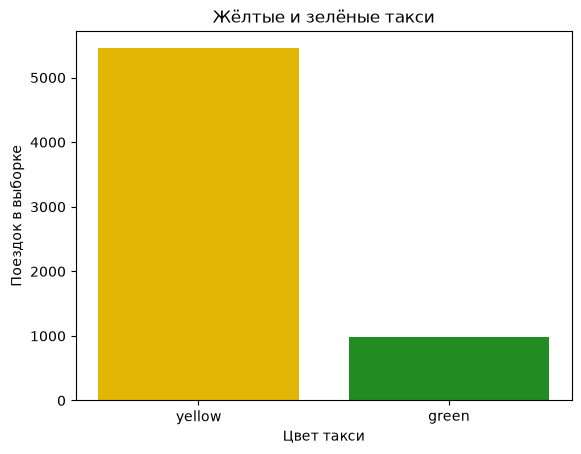

In [3]:
import matplotlib.pyplot as plt

TYPE_COLORS = {"yellow": "#E3B505", "green": "#228B22"}
bar_colors = color_counts.index.map(TYPE_COLORS)

fig, ax = plt.subplots()
ax.bar(
    color_counts.index,
    color_counts.values,
    color=bar_colors,
)

ax.set_xlabel("Цвет такси")
ax.set_ylabel("Поездок в выборке")
ax.set_title("Жёлтые и зелёные такси")

plt.show()

У столбцов общая нулевая отметка: длины удобно сравнивать. Методы `set_xlabel`, `set_ylabel` и `set_title` подписывают оси и рисунок, а `plt.show()` выводит фигуру. Подписи категорий остаются: цвет помогает чтению, но не заменяет название группы.

| Инструмент | Для чего будем использовать |
| --- | --- |
| `Matplotlib` | Основа: оси, столбцы, точки, линии и оформление |
| `Seaborn` | Сравнение групп и распределений; работает поверх `Matplotlib` |
| `Plotly` | Интерактивные подсказки, иерархии, 3D и карты |

Будем менять инструмент, когда появляется новая задача, сохраняя смысл показателей.

## **Категории и количества.**

**Где начинается больше поездок в нашей выборке?** Каждая строка теперь даёт вклад в счётчик района. `value_counts()` собирает такой счётчик, а `barh()` превращает его в горизонтальную столбчатую диаграмму (`horizontal bar chart`). Это тот же принцип, но категории теперь по вертикали, количества – по горизонтали.

`pickup_borough` – крупный район города, `pickup_zone` – более мелкая зона такси. Пропуски явно показываем отдельной категорией, чтобы не потерять часть выборки.

`figsize=(8, 4)` задаст размер фигуры в дюймах. `ax.set(...)` позволяет сразу указать несколько подписей, `set_xlim(left=0)` оставит начало числовой оси в нуле. Добавим ненавязчивую сетку: `grid(axis="x", alpha=0.2)`. Прозрачность `alpha` меняется от 0 до 1.

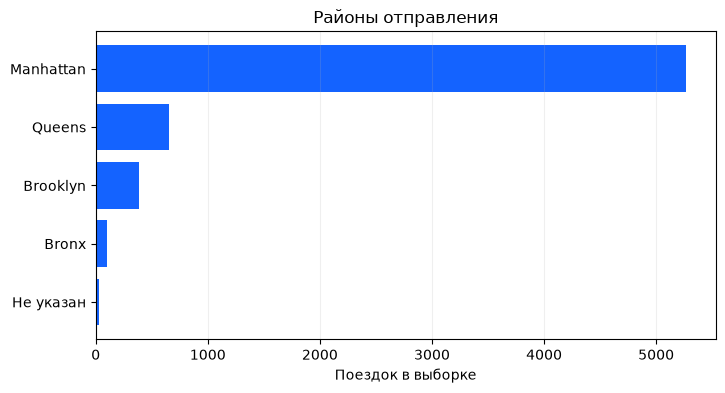

In [4]:
borough_counts = taxi["pickup_borough"].fillna("Не указан").value_counts()
ordered_counts = borough_counts.sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(ordered_counts.index, ordered_counts.values, color="#1463FF")

ax.set(xlabel="Поездок в выборке", title="Районы отправления")
ax.set_xlim(left=0)
ax.grid(axis="x", alpha=0.2)

plt.show()

`barh()` оставляет длинные названия слева: их не приходится поворачивать или сокращать.

### **Акцент и порядок.**

Покажем десять наиболее частых зон; это часть выборки, поэтому обозначим ограничение в заголовке. `bar_label` подпишет количества, `padding` оставит отступ, а `layout="constrained"` поможет разместить длинные названия без наложений.

Выделим лидера насыщенным синим, остальные столбцы сделаем светло-голубыми. Акцент создаёт контраст: один насыщенный столбец выделяется среди приглушённых.

После `sort_values()` количества идут по возрастанию, поэтому лидер стоит последним. Сначала создадим список светлых цветов для всех столбцов, затем заменим последний цвет через `colors[-1]`. `barh` применяет цвета в порядке переданных значений; последний столбец окажется сверху. Числовые подписи сохранят точные количества.

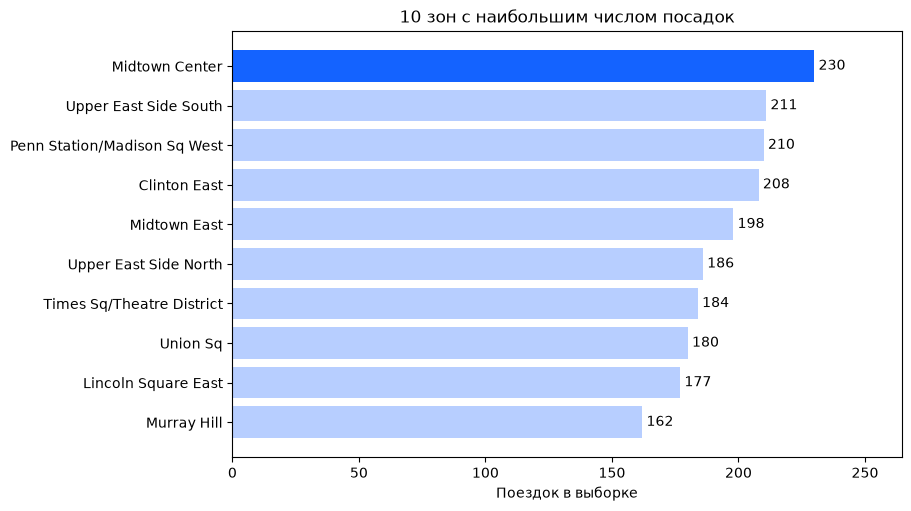

In [5]:
top_zones = taxi["pickup_zone"].dropna().value_counts().head(10).sort_values()
colors = ["#B7CEFF"] * len(top_zones)
# После сортировки по возрастанию последний столбец — лидер.
colors[-1] = "#1463FF"

fig, ax = plt.subplots(figsize=(9, 5), layout="constrained")
bars = ax.barh(top_zones.index, top_zones.values, color=colors)
ax.bar_label(bars, padding=3)

ax.set(xlabel="Поездок в выборке", title="10 зон с наибольшим числом посадок")
ax.set_xlim(0, top_zones.max() * 1.15)

plt.show()

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #ef4444; background-color: #fef2f2; color: #991b1b;">
<strong>Антипаттерн: обрезанное основание столбцов.</strong><br>Начало оси с 200 преувеличит разницу между 210 и 230: зритель сравнивает длины от основания. Для линий и точек ограниченный диапазон бывает полезен, поскольку значение передаёт положение, а не длина. Правило «любая ось всегда с нуля» неверно.
</div>

### **Круговая диаграмма (`pie chart`).**

На схеме несколько способов показать части целого:

- Круговая диаграмма (`pie chart`) – доли в виде секторов; начнём с неё.
- Кольцевая диаграмма (`donut chart`) – те же доли со свободным центром; построим следом.
- Иерархическая кольцевая диаграмма (`sunburst`) – вложенные группы; разберём в разделе интерактивности.
- Круг с выдвинутым сектором (`exploded pie`) – акцент на категории. Оставим только на схеме: смещение может затруднить сравнение долей.

<div>
<a href="../../Other/images/06_pie_charts.png"><img src="../../Other/images/06_pie_charts.png" width="1100" style="max-width: 100%; height: auto;" alt="Диаграммы частей целого: pie, donut, иерархическая sunburst и круг с выделенным сектором"></a>
</div>

**Как распределены способы оплаты во всей выборке?** Круговая диаграмма (`pie chart`) делит круг на секторы: угол сектора пропорционален доле. Она подходит, когда категории не пересекаются, вместе составляют целое и их немного.

Возьмём все поездки и сохраним категорию неизвестной оплаты. `pie` получает количества и сам переводит их в доли. `labels` подписывает категории, `autopct` задаёт формат процентов. Словарь `PAYMENT_COLORS` закрепит цвет за каждым способом оплаты. Эти цвета сохраним и в следующих сравнениях.

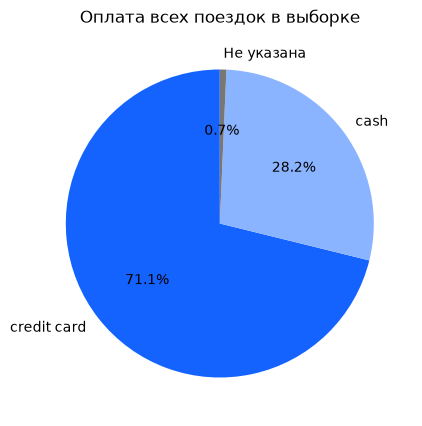

In [6]:
PAYMENT_COLORS = {"credit card": "#1463FF", "cash": "#8AB4FF", "Не указана": "#777777"}
payment_data = taxi.assign(payment=taxi["payment"].fillna("Не указана"))
payment_totals = payment_data["payment"].value_counts().reindex(PAYMENT_COLORS)

fig, ax = plt.subplots(figsize=(6, 5))
ax.pie(
    payment_totals,
    labels=payment_totals.index,
    autopct="%1.1f%%",
    colors=list(PAYMENT_COLORS.values()),
    startangle=90,
)

ax.set_title("Оплата всех поездок в выборке")

plt.show()

### **Кольцевая диаграмма (`donut chart`).**

Кольцевая диаграмма показывает те же доли, но оставляет центр свободным, например для общего числа поездок. У `pie` параметр `wedgeprops` задаёт оформление секторов; `width=0.45` превращает их в кольцо.

`plt.subplots(1, 2)` создаёт две области в одной строке и возвращает массив `axes`; обращаемся к ним по индексу. Для сравнения рядом покажем те же доли горизонтальными столбцами. Это один вопрос и одни расчёты, но два способа чтения.

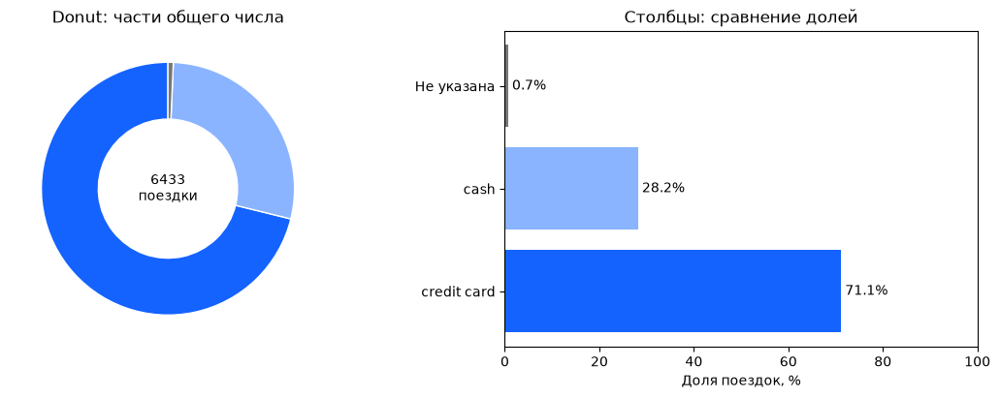

In [7]:
payment_percent = payment_totals / payment_totals.sum() * 100

fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout="constrained")
axes[0].pie(
    payment_totals,
    colors=list(PAYMENT_COLORS.values()),
    startangle=90,
    wedgeprops={"width": 0.45, "edgecolor": "white"},
)
axes[0].text(0, 0, f"{payment_totals.sum()}\nпоездки", ha="center", va="center")
axes[0].set_title("Donut: части общего числа")

bars = axes[1].barh(
    payment_percent.index, payment_percent, color=list(PAYMENT_COLORS.values())
)
axes[1].bar_label(bars, fmt="%.1f%%", padding=3)
axes[1].set(xlabel="Доля поездок, %", xlim=(0, 100), title="Столбцы: сравнение долей")

plt.show()

Близкие доли проще сравнить по длине столбцов, чем по углам секторов. Кольцо освобождает центр для числа, но не повышает точность сравнения.

Теперь сравним способы оплаты **между типами такси**.

---

### **Группированные столбцы (`grouped bar chart`) и `hue`.**

**Одинаково ли платят пассажиры жёлтых и зелёных такси?** Разобьём каждый тип такси по способу оплаты и поставим столбцы рядом. Это группированная столбчатая диаграмма (`grouped bar chart`).

`Seaborn` строит статистические графики поверх `Matplotlib`. `set_theme` задаёт оформление; `countplot` принимает таблицу в `data` и сам считает строки. `x` задаёт основные категории, **`hue` – подгруппы внутри каждой категории**.

Цвет теперь обозначает **оплату**, поэтому используем `PAYMENT_COLORS`. `palette` связывает категории с оттенками, `saturation=1` сохраняет их насыщенность, `order` и `hue_order` фиксируют порядок основных групп и подгрупп. `ax=ax` передаёт готовую область `Matplotlib`.

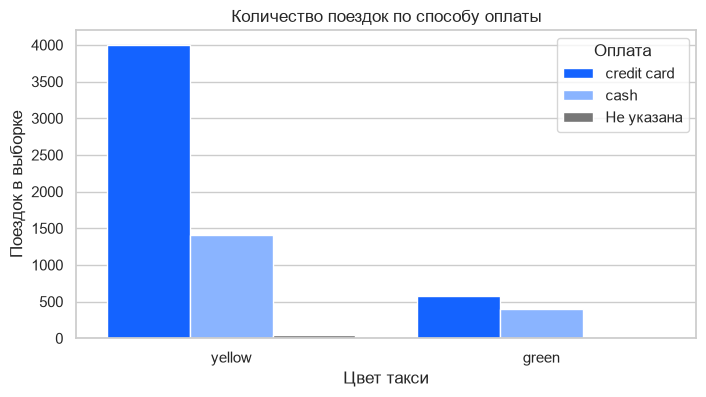

In [8]:
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(8, 4))
sns.countplot(
    data=payment_data,
    x="color",
    hue="payment",
    order=["yellow", "green"],
    hue_order=list(PAYMENT_COLORS),
    saturation=1,
    palette=PAYMENT_COLORS,
    ax=ax,
)

ax.set(
    xlabel="Цвет такси",
    ylabel="Поездок в выборке",
    title="Количество поездок по способу оплаты",
)
ax.legend(title="Оплата")

plt.show()

`color="blue"` просто покрасил бы элементы в синий. `hue="payment"` связывает цвет с данными и разделяет наблюдения.

### **Столбцы с накоплением: `stacked bar chart`.**

В `grouped bar` способы оплаты стояли рядом: их удобно сравнивать по длине от общего нуля.

Теперь вопрос другой: **сколько всего поездок в каждой группе и из каких способов оплаты складывается это число?** Поставим сегменты друг над другом. Получится столбчатая диаграмма с накоплением (`stacked bar chart`).

Сначала подготовим таблицу: строки – типы такси, столбцы – способы оплаты, значения – количества поездок.

In [9]:
payment_counts = (
    payment_data.groupby(["color", "payment"])
    .size()
    .unstack(fill_value=0)
    .reindex(["yellow", "green"])
)
payment_counts

payment,cash,credit card,Не указана
color,,,
yellow,1412,4000,39
green,400,577,5


`DataFrame.plot.bar(stacked=True)` складывает сегменты в один столбец. Высота всего столбца равна сумме строки, высота каждого сегмента – количеству поездок с данным способом оплаты. Этот интерфейс `Pandas` использует `Matplotlib`; передадим ему знакомый `ax`.

Такой график подходит для **непересекающихся частей одного целого**. Одну поездку относим только к одному способу оплаты, поэтому их количества можно складывать.

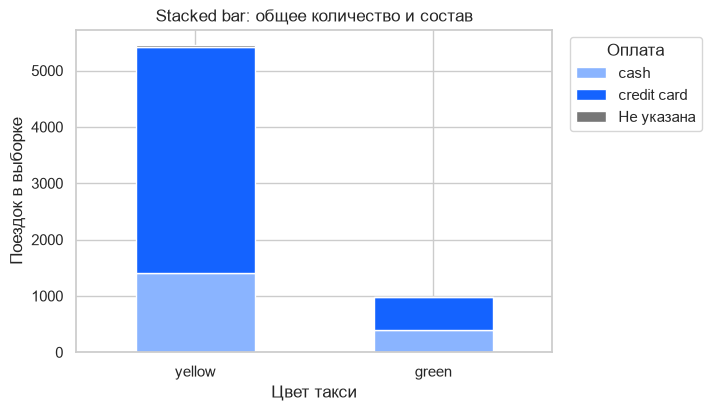

In [10]:
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
payment_counts.plot.bar(
    stacked=True,
    ax=ax,
    rot=0,
    color=[PAYMENT_COLORS[name] for name in payment_counts.columns],
)

ax.set(
    xlabel="Цвет такси",
    ylabel="Поездок в выборке",
    title="Stacked bar: общее количество и состав",
)
ax.legend(title="Оплата", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.show()

### **Нормированные столбцы: `100% stacked bar chart`.**

Жёлтых такси в выборке больше, поэтому их столбец выше. Теперь спросим: **какая доля поездок оплачена картой внутри каждого типа такси?**

В `payment_counts` одна строка соответствует типу такси. Сначала найдём сумму строки – все поездки этого типа. Затем разделим каждое количество в строке на эту сумму и умножим на 100: `30 / 50 * 100 = 60%`.

После такого расчёта сумма каждой строки равна 100%. График этих долей называют нормированной столбчатой диаграммой с накоплением (`100% stacked bar chart`).

`sum(axis=1)` складывает столбцы внутри строки. У `.div(..., axis=0)` другая задача: сопоставить делитель с **индексом строки**, то есть с типом такси. Так каждая группа делится на своё количество поездок.

In [11]:
trips_per_color = payment_counts.sum(axis=1)

# Сопоставляем итог каждой группы со строкой yellow или green.
payment_share = payment_counts.div(trips_per_color, axis=0) * 100
payment_share.round(1)

payment,cash,credit card,Не указана
color,,,
yellow,25.9,73.4,0.7
green,40.7,58.8,0.5


Передадим проценты тому же `plot.bar(stacked=True)`. Сам `stacked=True` только складывает сегменты; доли мы уже рассчитали.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #ef4444; background-color: #fef2f2; color: #991b1b;">
<strong>Антипаттерн: принимаем долю за размер группы.</strong><br>10 и 10 000 поездок дадут одинаковую высоту 100%. Такой график сравнивает состав; для объёма нужны исходные количества. Сегменты внутри накопления имеют разные основания: для точного сравнения одного способа оплаты удобнее отдельные столбцы.
</div>

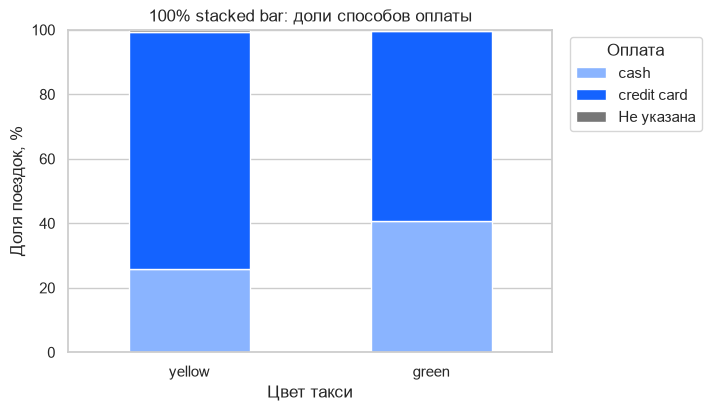

In [12]:
fig, ax = plt.subplots(figsize=(7, 4), layout="constrained")
payment_share.plot.bar(
    stacked=True,
    ax=ax,
    rot=0,
    color=[PAYMENT_COLORS[name] for name in payment_share.columns],
)

ax.set(
    xlabel="Цвет такси",
    ylabel="Доля поездок, %",
    title="100% stacked bar: доли способов оплаты",
    ylim=(0, 100),
)
ax.legend(title="Оплата", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.show()

### **Количество или среднее?**

Тот же вид столбцов может отвечать на другой вопрос: **какова средняя базовая стоимость поездки в каждой группе?** `sns.barplot` группирует строки и по умолчанию вычисляет среднее `y`; `sns.countplot` считает строки. В `Matplotlib` `ax.bar` вообще не агрегирует – рисует переданные числа.

Зададим `estimator="mean"` явно. `errorbar=None` убирает интервал неопределённости оценки, который `Seaborn` обычно добавляет. Сейчас показываем только средние нашей выборки. `saturation=1` сохраняет выбранные оттенки без приглушения. `hue` повторяет `x` ради устойчивой раскраски; новая подгруппа здесь не возникает, поэтому легенду убираем.

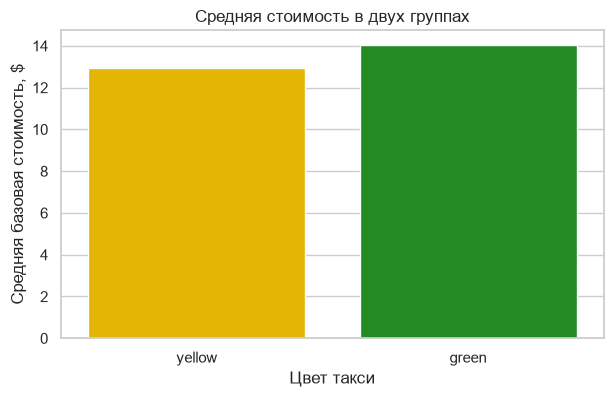

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=taxi,
    x="color",
    y="fare",
    hue="color",
    estimator="mean",
    errorbar=None,
    palette=TYPE_COLORS,
    saturation=1,
    legend=False,
    ax=ax,
)

ax.set(
    xlabel="Цвет такси",
    ylabel="Средняя базовая стоимость, $",
    title="Средняя стоимость в двух группах",
)

plt.show()

Одно среднее скрывает разброс: большинство поездок могут стоить мало, а несколько дорогих заметно поднимут среднее. Чтобы увидеть, какие значения встречаются и насколько они различаются, перейдём к распределениям.

---

## **Распределение значений: гистограмма (`histogram`).**

Здесь построим обычную гистограмму (`histogram`). Остальные варианты рассмотрим только на схеме:

- С накоплением (`stacked histogram`) – вклад групп в каждый интервал.
- С наложением (`overlaid histogram`) – распределения нескольких групп на общей шкале.
- Контурная (`step histogram`) – границы столбцов без заливки.

Для сравнения групп границы интервалов должны совпадать.

<div>
<a href="../../Other/images/06_histogram_charts.png"><img src="../../Other/images/06_histogram_charts.png" width="1100" style="max-width: 100%; height: auto;" alt="Гистограммы: обычная, с накоплением, с наложением групп и контурная"></a>
</div>

**Какие расстояния встречаются чаще?** Одно среднее расстояние этого не показывает. Гистограмма делит числовую ось на интервалы – **бины** – и считает, сколько наблюдений попало в каждый из них.

В столбчатой диаграмме мы сравнивали отдельные категории. Здесь столбцы обозначают соседние участки числовой шкалы. Передаём `hist` исходные расстояния: заранее группировать их или считать частоты не нужно.

### **Что задаёт `bins`?**

Гистограмма сама вычисляет разбиение и частоты. Параметр `bins` позволяет управлять разбиением:

| Вызов | Что происходит |
| --- | --- |
| `ax.hist(data)` | Используется настройка `Matplotlib`: обычно 10 интервалов |
| `ax.hist(data, bins=30)` | Строятся 30 интервалов одинаковой ширины; границы вычисляются автоматически |
| `ax.hist(data, bins="auto")` | Правило подбирает число интервалов по данным |
| `ax.hist(data, bins=[0, 5, 10, 20, 50])` | Мы явно задаём границы четырёх интервалов |

В последней строке интервалы имеют разную ширину. По умолчанию столбец показывает количество, а широкий интервал может собрать больше значений просто из-за своей ширины. Для сравнения плотности используют нормирование, к которому вернёмся ниже.

**Зачем тогда писать `bins=10` и `bins=45`?** Чтобы на одинаковых данных увидеть, как детализация меняет рисунок. Мы задаём только число интервалов; границы и частоты всё равно считает библиотека.

`subplots(1, 2)` уже знаком по сравнению `donut` и столбцов. `sharex=True` теперь задаёт общую горизонтальную шкалу: обе панели показывают один диапазон расстояний.

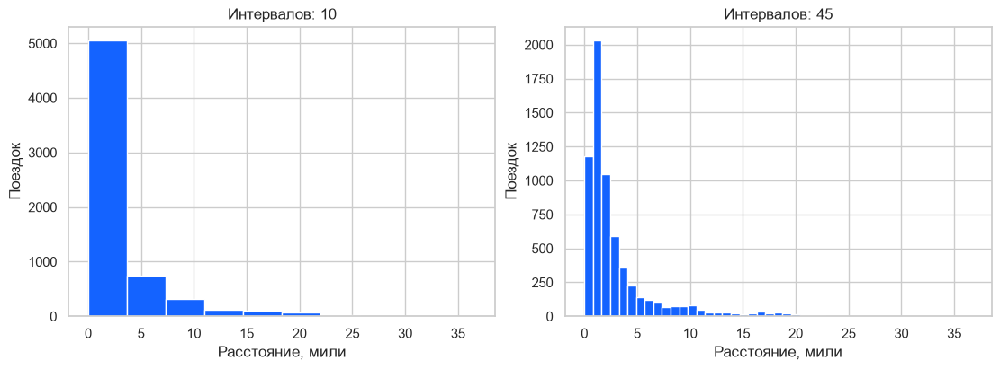

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharex=True, layout="constrained")
for ax, bins in zip(axes, [10, 45]):
    ax.hist(taxi["distance"], bins=bins, color="#1463FF", edgecolor="white")
    ax.set(xlabel="Расстояние, мили", ylabel="Поездок", title=f"Интервалов: {bins}")

plt.show()

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #3b82f6; background-color: #eff6ff; color: #1e40af;">
<strong>Приём: проверяем устойчивость формы.</strong><br>Сравним несколько разбиений одной выборки: крупные интервалы могут слить разные скопления, а мелкие – превратить случайные колебания в «пики». Вывод о форме должен выдерживать разумное изменение <code>bins</code>.<br><a href="https://seaborn.pydata.org/tutorial/distributions.html#choosing-the-bin-size"><code>Seaborn</code>: выбор интервалов</a>
</div>

Большинство поездок короткие, но есть длинный правый хвост. Редкие большие значения сильнее влияют на среднее, чем на медиану. Сравним их.

In [15]:
taxi["distance"].agg(["median", "mean", "max"]).round(2)

median     1.64
mean       3.02
max       36.70
Name: distance, dtype: float64

### **Логарифмическая шкала.**

Если редкие значения почти не видны, можно изменить шкалу. На логарифмической оси одинаковые расстояния означают одинаковое **отношение**: от 1 до 10 столько же места, сколько от 10 до 100.

Покажем логарифмическую шкалу частот, сохранив исходные интервалы расстояния. Это не гистограмма логарифмов расстояния. Нулевые частоты на такой оси не отображаются.

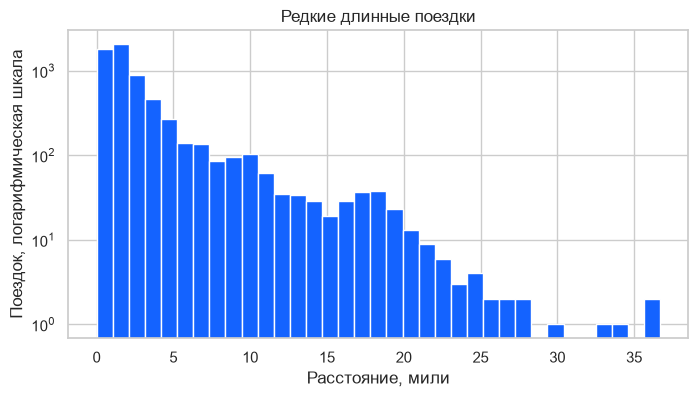

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(taxi["distance"], bins=35, color="#1463FF", edgecolor="white")
ax.set_yscale("log")

ax.set(
    xlabel="Расстояние, мили",
    ylabel="Поездок, логарифмическая шкала",
    title="Редкие длинные поездки",
)

plt.show()

### **Доля ниже порога: `ECDF`.**

**Какая доля поездок не длиннее пяти миль?** `ECDF` (`empirical cumulative distribution function`, эмпирическая функция распределения) отвечает на этот вопрос: число наблюдений **не больше порога**, делённое на размер выборки.

Возьмём расстояния `1, 2, 2, 5, 10` миль. Не больше двух миль проехали 3 из 5 машин (60%), не больше пяти – 4 из 5 (80%). Каждая двойка считается отдельным наблюдением.

In [17]:
example_distances = pd.Series([1, 2, 2, 5, 10])
thresholds = [1, 2, 5, 10]
ecdf_example = pd.DataFrame(
    {
        "Порог, мили": thresholds,
        "Наблюдений не больше порога": [
            example_distances.le(value).sum() for value in thresholds
        ],
    }
)
ecdf_example["Накопленная доля"] = ecdf_example["Наблюдений не больше порога"] / len(
    example_distances
)
ecdf_example

,"Порог, мили",Наблюдений не больше порога,Накопленная доля
0,1,1,0.2
1,2,3,0.6
2,5,4,0.8
3,10,5,1.0


По горизонтали `ECDF` откладывает порог, по вертикали – накопленную долю. Получается лестница: в нашей выборке каждое наблюдение добавляет `1 / 5 = 0.2`. В точке 2 два наблюдения, поэтому скачок равен 0.4. Между значениями доля не меняется; после максимума она равна 1.

`sns.ecdfplot` строит эту лестницу без интервалов и сглаживания. `hue` создаст отдельную кривую для каждого типа такси, считая доли внутри группы. Через `axvline` отметим порог в пять миль.

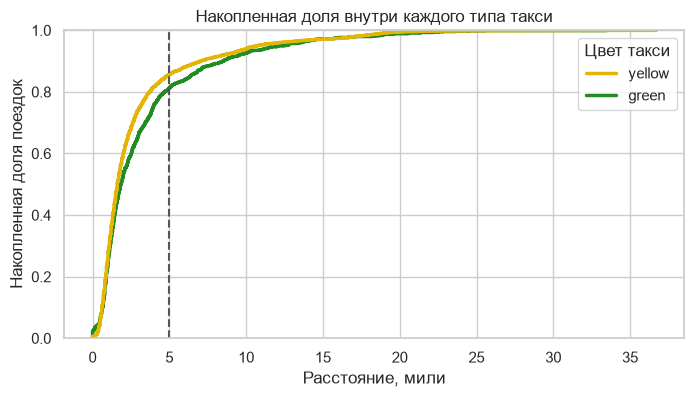

color
green     0.813
yellow    0.858
Name: up_to_5, dtype: float64

In [18]:
fig, ax = plt.subplots(figsize=(8, 4))
sns.ecdfplot(
    data=taxi, x="distance", hue="color", palette=TYPE_COLORS, linewidth=2.5, ax=ax
)
ax.axvline(5, color="#555555", linestyle="--", label="5 миль")

ax.set(
    xlabel="Расстояние, мили",
    ylabel="Накопленная доля поездок",
    title="Накопленная доля внутри каждого типа такси",
)
ax.get_legend().set_title("Цвет такси")

plt.show()

taxi.assign(up_to_5=taxi["distance"].le(5)).groupby("color")["up_to_5"].mean().round(3)

### **`ECDF` и процентили.**

Распределение можно читать в двух направлениях:

- **От значения к доле:** для порога 5 миль `ECDF` нашей маленькой выборки даёт 80%.
- **От доли к значению:** для уровня 80% ищем первый порог, где `ECDF` достигла этого уровня. Получаем 5 миль.

Во втором случае ищем **процентиль**: значение для заданной накопленной доли. 50-й процентиль – медиана, 25-й и 75-й – первый и третий квартили. У квантилей долю записывают от 0 до 1: `0.8` вместо 80%.

Есть тонкость: библиотека может интерполировать между наблюдениями. [`Pandas` по умолчанию](https://pandas.pydata.org/docs/reference/api/pandas.Series.quantile.html) даёт для 80-го процентиля `1, 2, 2, 5, 10` значение 6. Поэтому результат `quantile` не всегда совпадёт с порогом, прочитанным по ступеньке `ECDF`.

---

## **Сравнение распределений.**

**Чем отличаются поездки из центра и из аэропортов?** Выберем три зоны: Midtown Center, JFK Airport и LaGuardia Airport. Сравним базовую стоимость; сначала проверим размеры групп. Различия могут быть связаны с направлениями и условиями поездок, а не только с местом посадки.

In [19]:
ZONE_ORDER = ["Midtown Center", "LaGuardia Airport", "JFK Airport"]
ZONE_COLORS = dict(zip(ZONE_ORDER, ["#1463FF", "#8AB4FF", "#153EAB"]))
zone_trips = taxi.loc[taxi["pickup_zone"].isin(ZONE_ORDER)].copy()
zone_trips.groupby("pickup_zone")["fare"].agg(["size", "median", "mean"]).reindex(
    ZONE_ORDER
).round(1)

,size,median,mean
pickup_zone,,,
Midtown Center,230,9.5,12.5
LaGuardia Airport,146,29.5,30.5
JFK Airport,151,52.0,44.5


### **Ящик с усами (`box plot`).**

Начнём с ящика с усами (`box plot`), затем разберём оценку плотности и на её основе построим скрипичные диаграммы (`violin plot`), в том числе с разделением на подгруппы (`split violin`). Ещё два варианта на схеме оставим как обзор:

- Группированные ящики (`grouped box plot`) – несколько коробок рядом для каждой категории, по знакомому принципу группированных столбцов.
- Гребневой график (`ridgeline plot`) – кривые плотности, расположенные рядами. Кратко обсудим после плотности, без отдельного построения.

<div>
<a href="../../Other/images/06_box_charts.png"><img src="../../Other/images/06_box_charts.png" width="1100" style="max-width: 100%; height: auto;" alt="Сравнение распределений: boxplot, группы коробок, violin, split violin и ridgeline"></a>
</div>

`Boxplot` компактно сравнивает несколько распределений. Линия внутри коробки – медиана; края – первый и третий квартили. Коробка охватывает середину распределения: от 25-го до 75-го процентиля. Разность квартилей называют межквартильным размахом, `IQR`.

По умолчанию усы `Seaborn` идут до крайних наблюдений в пределах 1,5 `IQR` от краёв коробки. Это не обязательно минимум и максимум. Отдельные точки за усами не становятся ошибками автоматически.

Здесь `x` – числовая стоимость, `y` – зона: горизонтальные коробки оставляют место длинным названиям.

Цвет теперь различает **зоны**. Палитра `ZONE_COLORS` будет одинаковой у `boxplot` и `violin`; тип такси в этих рисунках цветом не кодируется.

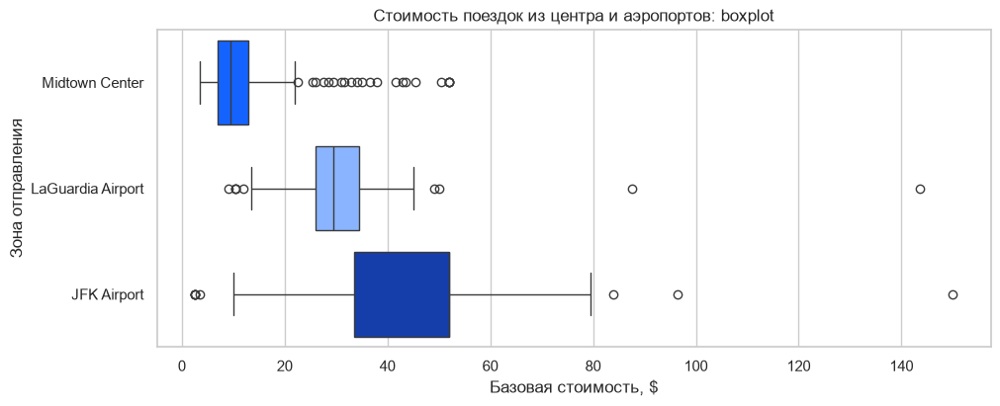

In [20]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
sns.boxplot(
    data=zone_trips,
    x="fare",
    y="pickup_zone",
    hue="pickup_zone",
    order=ZONE_ORDER,
    saturation=1,
    palette=ZONE_COLORS,
    legend=False,
    ax=ax,
)

ax.set(
    xlabel="Базовая стоимость, $",
    ylabel="Зона отправления",
    title="Стоимость поездок из центра и аэропортов: boxplot",
)

plt.show()

### **Почему медиана совпала с `Q3`?**

У JFK линия медианы слилась с правым краем коробки. Проверим это числами: `quantile` вычислит `Q1`, `Q2` и `Q3` для базовой стоимости. Укажем доли `0.25`, `0.5` и `0.75`, а также посчитаем поездки с суммой ровно 52 доллара.

In [21]:
jfk_fares = zone_trips.loc[zone_trips["pickup_zone"].eq("JFK Airport"), "fare"]
jfk_quartiles = jfk_fares.quantile([0.25, 0.5, 0.75])
print("Поездок из JFK:", len(jfk_fares))
print("Из них с базовой стоимостью ровно 52 $:", jfk_fares.eq(52).sum())
jfk_quartiles.rename(
    index={0.25: "Q1 (25%)", 0.5: "Медиана / Q2 (50%)", 0.75: "Q3 (75%)"}
).to_frame("Базовая стоимость, $")

Поездок из JFK: 151
Из них с базовой стоимостью ровно 52 $: 73


,"Базовая стоимость, $"
Q1 (25%),33.5
Медиана / Q2 (50%),52.0
Q3 (75%),52.0


Получили **`Q1` = 33.5 доллара, медиану = 52 доллара и `Q3` = 52 доллара**. Коробка идёт от 33.5 до 52, а линия медианы тоже стоит на 52, поэтому совпадает с её правым краем.

Разным процентилям не обязательно соответствуют разные значения. Повторяющаяся сумма 52 занимает сразу несколько позиций в упорядоченной выборке. Из совпадения `Q2` и `Q3` не следует, что между ними «нет поездок»: наблюдения могут иметь одну и ту же стоимость.

### **Ядерная оценка плотности (`KDE`).**

**Около каких сумм скапливаются поездки?** `KDE` (`kernel density estimation`, ядерная оценка плотности) оценивает плотность распределения; её изображают кривой плотности (`density plot`). Поместим возле каждого наблюдения гладкий «бугорок», сложим их и нормируем общую площадь к единице. Где значений больше, кривая выше.

`KDE` строится по исходным наблюдениям, а не соединяет вершины гистограммы.

**Как читать `KDE`?** Высота показывает плотность, а **площадь под кривой на интервале** – оценку доли наблюдений. Площадь 0.3 между 10 и 20 долларами означает около 30% значений в этом диапазоне.

Площадь под всей кривой равна 1; высота может быть больше 1. Для стоимости в долларах единица плотности – `1/$`. У `ECDF` долю читаем по высоте, у `KDE` – по площади.

### **Ширина сглаживания.**

Ширину «бугорков» называют `bandwidth`. Узкие сохраняют детали, но могут создавать случайные пики; широкие сглаживают колебания, но могут слить разные скопления.

Сравним две `KDE` для поездок из JFK. `bw_adjust` умножает автоматически выбранную ширину: `0.4` сужает её, `1.2` расширяет. Цвет и тип линии обозначают настройку сглаживания.

На тех же осях построим гистограмму с `stat="density"`: частоты делятся на размер выборки и ширину интервала, поэтому общая площадь столбцов равна 1. Теперь её шкала сопоставима с `KDE`; аналог в `Matplotlib` – `density=True`.

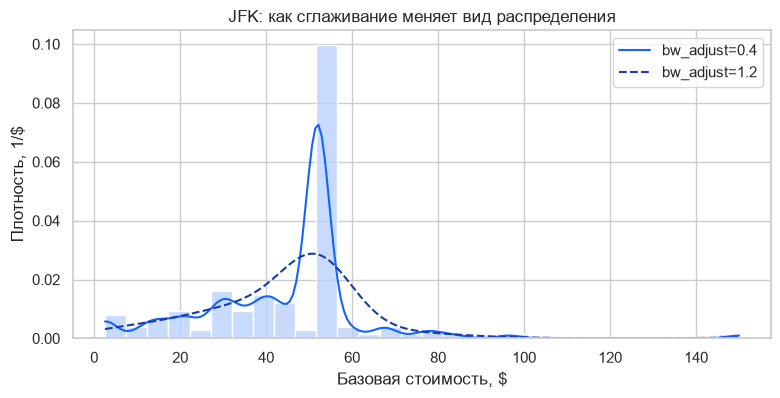

In [22]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(x=jfk_fares, bins=30, stat="density", color="#B7CEFF", ax=ax)
for bandwidth, color, style in [(0.4, "#1463FF", "-"), (1.2, "#153EAB", "--")]:
    sns.kdeplot(
        x=jfk_fares,
        bw_adjust=bandwidth,
        cut=0,
        color=color,
        linestyle=style,
        label=f"bw_adjust={bandwidth}",
        ax=ax,
    )

ax.set(
    xlabel="Базовая стоимость, $",
    ylabel="Плотность, 1/$",
    title="JFK: как сглаживание меняет вид распределения",
)
ax.legend()

plt.show()

`cut=0` ограничивает рисунок диапазоном наблюдений, но не исправляет оценку у границ. Часть кривой может остаться за краями, поэтому площадь **видимого** участка бывает меньше 1.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #ef4444; background-color: #fef2f2; color: #991b1b;">
<strong>Антипаттерн: принимаем сглаживание за свойство данных.</strong><br>Пик около 52 долларов получился из повторяющейся точной суммы. <code>KDE</code> превращает её в плавный бугорок и скрывает дискретность цен. Проверяем пики при нескольких <code>bw_adjust</code> и сверяем с исходными значениями.<br><a href="https://seaborn.pydata.org/tutorial/distributions.html#kernel-density-estimation-pitfalls"><code>Seaborn</code>: ограничения <code>KDE</code></a>
</div>

### **Скрипичная диаграмма (`violin plot`).**

`Violin plot` разворачивает кривую плотности вдоль числовой оси и зеркально отражает её. Получается «скрипка»: в широких местах значения более сконцентрированы, в узких – менее. Две половины показывают одну и ту же плотность, а не две группы.

![Форма `violin plot`: одно, два и несколько скоплений значений](../../Other/images/06_violine_plots.png)

На схеме слева один пик (`unimodal`), в середине два (`bimodal`), справа несколько (`multimodal`). Близкие медианы и квартили могут скрывать разную форму. В этом и смысл `violin`: видеть скопления, которые коробка не передаёт.

Это иллюстрация формы, а не результаты нашего датасета. Белая точка обозначает медиану, прямоугольник – `IQR`. Усы **на схеме** подписаны как минимум и максимум; у нашего `boxplot` используется правило 1,5 `IQR`. В следующем примере вместо усов внутри `violin` будут только линии квартилей.

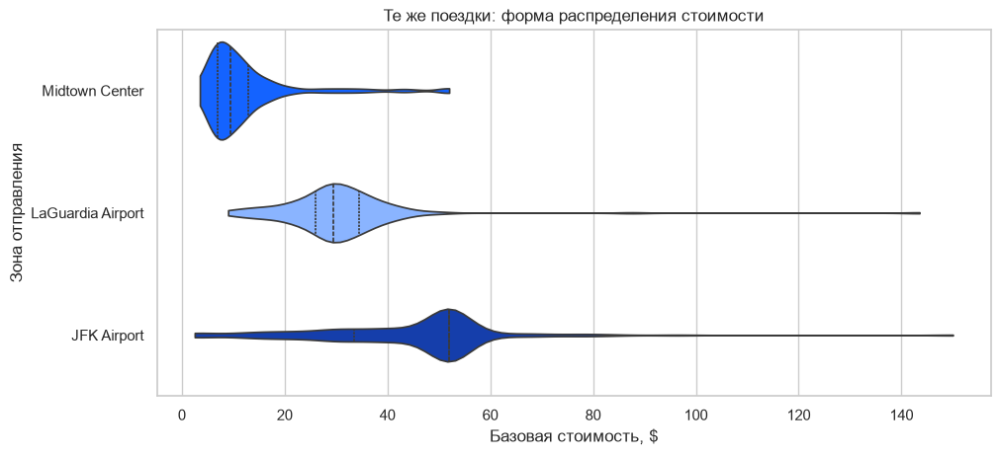

In [23]:
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
sns.violinplot(
    data=zone_trips,
    x="fare",
    y="pickup_zone",
    hue="pickup_zone",
    order=ZONE_ORDER,
    saturation=1,
    palette=ZONE_COLORS,
    legend=False,
    inner="quart",
    cut=0,
    bw_adjust=0.6,
    density_norm="area",
    common_norm=True,
    ax=ax,
)

ax.set(
    xlabel="Базовая стоимость, $",
    ylabel="Зона отправления",
    title="Те же поездки: форма распределения стоимости",
)

plt.show()

У Midtown Center значения сконцентрированы возле небольших сумм, у JFK – около 52 долларов. `inner="quart"` отмечает три квартиля.

`density_norm="area", common_norm=True` задают одинаковую площадь скрипок: **ширина не показывает размер группы**. Количества мы вывели перед сравнением; для малых групп полезно добавить отдельные наблюдения.

### **Разделённая скрипичная диаграмма (`split violin plot`).**

**Различается ли распределение стоимости при оплате картой и наличными внутри одной зоны?** У обычной скрипки две половины зеркальны. В `split violin` каждая половина показывает свою подгруппу: можно сопоставить их форму на одной числовой шкале.

Сохраним знакомые зоны и `fare`, добавим только способ оплаты. Оставим две известные категории и выведем размеры групп: гладкая форма сама по себе не показывает, сколько за ней наблюдений.

In [24]:
PAYMENT_ORDER = ["credit card", "cash"]
split_trips = zone_trips.loc[zone_trips["payment"].isin(PAYMENT_ORDER)].copy()
print("Поездок без известного способа оплаты:", len(zone_trips) - len(split_trips))

split_counts = (
    split_trips.groupby(["pickup_zone", "payment"])
    .size()
    .unstack(fill_value=0)
    .reindex(index=ZONE_ORDER, columns=PAYMENT_ORDER)
)
split_counts

Поездок без известного способа оплаты: 7


payment,credit card,cash
pickup_zone,,
Midtown Center,175,53
LaGuardia Airport,117,28
JFK Airport,94,53


Знакомый `hue="payment"` задаёт подгруппы, а [`split=True`](https://seaborn.pydata.org/generated/seaborn.violinplot.html) размещает их по разные стороны оси каждой скрипки. При горизонтальном расположении первая категория из `hue_order` будет сверху, вторая – снизу. Цвета оплаты берём из `PAYMENT_COLORS`.

`density_norm="width"` задаёт каждой половине одинаковую максимальную ширину: сравниваем форму, а не количество поездок. `inner="quart"` отмечает квартили каждой подгруппы; настройки сглаживания оставим прежними.

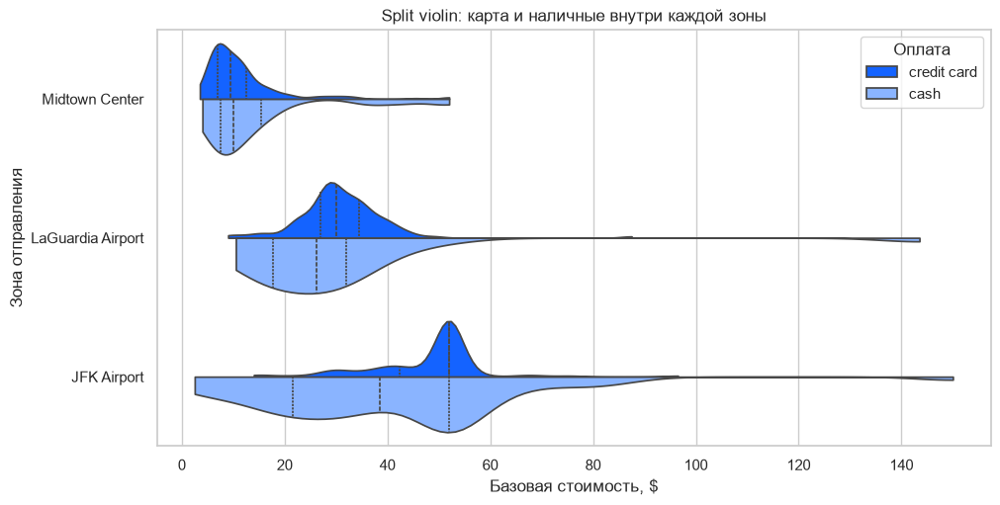

In [25]:
split_fig, split_ax = plt.subplots(figsize=(10, 5), layout="constrained")
sns.violinplot(
    data=split_trips,
    x="fare",
    y="pickup_zone",
    hue="payment",
    order=ZONE_ORDER,
    hue_order=PAYMENT_ORDER,
    split=True,
    palette=PAYMENT_COLORS,
    saturation=1,
    inner="quart",
    cut=0,
    bw_adjust=0.6,
    density_norm="width",
    common_norm=False,
    ax=split_ax,
)

split_ax.set(
    xlabel="Базовая стоимость, $",
    ylabel="Зона отправления",
    title="Split violin: карта и наличные внутри каждой зоны",
)
split_ax.legend(title="Оплата")

plt.show()

Сравниваем половины **внутри одной зоны**: где находятся пики, насколько длинны хвосты, где проходят линии квартилей. У JFK при оплате картой виден узкий пик около 52 долларов, при оплате наличными распределение шире. Различие форм не доказывает, что способ оплаты меняет цену: у групп могут различаться направления и расстояния поездок.

Ещё один вариант с начальной схемы – **гребневой график (`ridgeline plot`)**: кривые плотности расположены рядами на общей числовой шкале, иногда с перекрытием. Он удобен, когда распределений много и хочется увидеть сдвиг пиков между группами. Здесь ограничимся этим ориентиром; [пример `Seaborn`](https://seaborn.pydata.org/examples/kde_ridgeplot.html) показывает построение.

---

## **Диаграмма рассеяния (`scatter plot`).**

Диаграмма рассеяния показывает связь двух величин. Здесь последовательно построим обычные точки, разделим их по группам, добавим размер и перейдём к подсчёту точек в ячейках. Последнюю панель схемы, с распределениями по краям, разберём словами после этих примеров.

<div>
<a href="../../Other/images/06_scatter_charts.png"><img src="../../Other/images/06_scatter_charts.png" width="1100" style="max-width: 100%; height: auto;" alt="Точечные диаграммы: обычная, с группировкой цветом, пузырьковая, hexbin и с распределениями по краям"></a>
</div>

**Как соотносятся расстояние и базовая стоимость?** Теперь у каждой поездки нужны сразу два числа. `Scatter plot` размещает одну поездку одной точкой: расстояние задаёт координату `x`, стоимость – `y`.

`ax.scatter(x, y)` не агрегирует строки. Не соединяем точки линией: порядок строк не описывает путь одной машины. `s` задаёт площадь маркера, `alpha` – прозрачность; небольшие полупрозрачные точки помогают увидеть наложения.

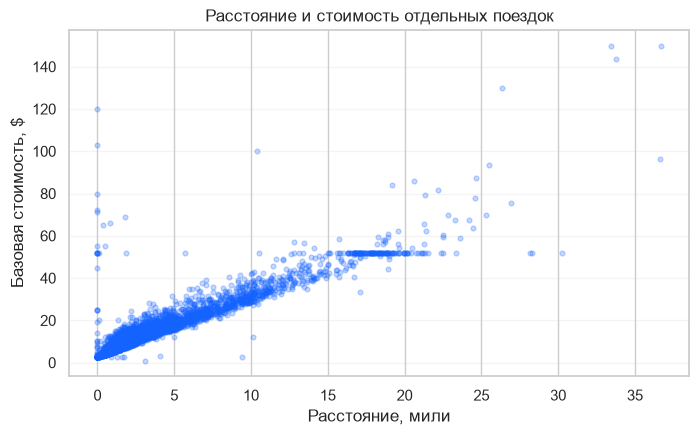

In [26]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(taxi["distance"], taxi["fare"], s=12, alpha=0.25, color="#1463FF")

ax.set(
    xlabel="Расстояние, мили",
    ylabel="Базовая стоимость, $",
    title="Расстояние и стоимость отдельных поездок",
)
ax.grid(axis="y", alpha=0.2)

plt.show()

Основная масса точек сосредоточена возле коротких поездок. Видны и необычные сочетания стоимости и расстояния. График показывает связь, но сам по себе не объясняет тариф и не доказывает причинность.

Не обрезаем «неудобные» точки молча. Вернёмся в таблицу и проверим записи с нулевым расстоянием: их могло породить несколько причин, включая особенности регистрации.

In [27]:
zero_distance = taxi["distance"].eq(0)
print("Поездок с нулевым расстоянием:", zero_distance.sum())
taxi.loc[zero_distance, ["distance", "fare", "total"]].head()

Поездок с нулевым расстоянием: 51


,distance,fare,total
42,0.0,80.0,100.38
120,0.0,2.5,4.30
622,0.0,120.0,166.00
670,0.0,2.5,6.30
970,0.0,45.0,50.30


### **Цвет или отдельные панели.**

Добавим к связи тип такси. Знакомый `hue="color"` разделит точки по группам. Если цвета перекрываются, вынесем группы в отдельные панели с одинаковыми шкалами – такой приём называют малыми кратными (`small multiples`).

`relplot(kind="scatter")` создаёт всю фигуру сам; `col` выбирает столбец для панелей. Поэтому здесь не передаём `ax`. `hue` можно использовать вместе с `col`, сохраняя знакомые цвета.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #ef4444; background-color: #fef2f2; color: #991b1b;">
<strong>Антипаттерн: незаметно меняем шкалы панелей.</strong><br>Для сравнения групп оставляем одинаковые диапазоны обеих осей. Иначе маленький разброс одной группы можно растянуть до размера большого разброса другой. Если масштабы различаются намеренно, это нужно явно обозначить.
</div>

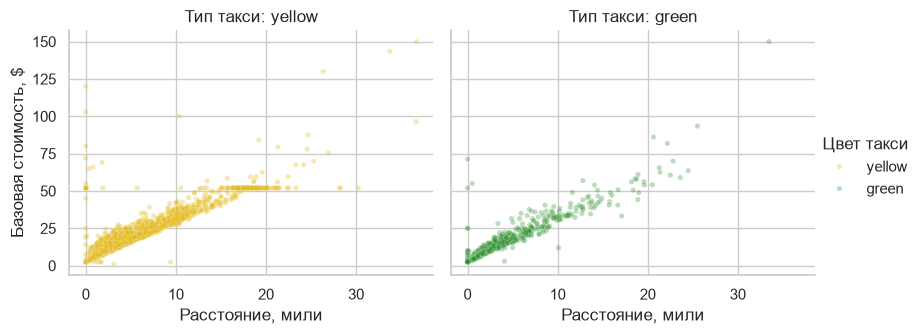

In [28]:
scatter_grid = sns.relplot(
    data=taxi,
    x="distance",
    y="fare",
    hue="color",
    col="color",
    kind="scatter",
    col_order=["yellow", "green"],
    palette=TYPE_COLORS,
    s=14,
    alpha=0.3,
    height=3.5,
    aspect=1.2,
)
scatter_grid.set_axis_labels("Расстояние, мили", "Базовая стоимость, $")
scatter_grid.set_titles("Тип такси: {col_name}")
scatter_grid.legend.set_title("Цвет такси")

plt.show()

На общих шкалах видно положение и разброс групп. Плотность точек зависит ещё и от числа наблюдений: жёлтых такси в выборке больше.

### **Третий показатель: `bubble chart`.**

**Какие зоны сочетают большие средние расстояния, высокую стоимость и много поездок?** Сначала изменим единицу наблюдения: одна строка новой таблицы будет одной зоной. Для неё посчитаем среднее расстояние, среднюю базовую стоимость и число поездок.

Оставим зоны хотя бы с 20 наблюдениями, чтобы единичная дорогая поездка не определяла среднее целой зоны. Это явное ограничение демонстрации, а не гарантия надёжности средних.

In [29]:
zone_summary = (
    taxi.groupby(["pickup_borough", "pickup_zone"])
    .agg(
        mean_distance=("distance", "mean"),
        mean_fare=("fare", "mean"),
        trips=("fare", "size"),
    )
    .reset_index()
)

bubble_zones = zone_summary.loc[zone_summary["trips"].ge(20)]
print("Зон на графике:", len(bubble_zones), "из", len(zone_summary))
bubble_zones.head()

Зон на графике: 64 из 194


,pickup_borough,pickup_zone,mean_distance,mean_fare,trips
39,Brooklyn,Boerum Hill,2.812857,11.761905,21
42,Brooklyn,Brooklyn Heights,3.115588,13.275294,34
55,Brooklyn,Downtown Brooklyn/MetroTech,3.358108,15.849730,37
64,Brooklyn,Fort Greene,2.830769,12.859487,39
72,Brooklyn,Park Slope,2.773636,12.082727,22


Пузырьковая диаграмма (`bubble chart`) – `scatter plot` с числовым показателем в размере точки. У `Seaborn` `size="trips"` связывает площадь маркера с количеством поездок, а `sizes` задаёт диапазон площадей. Подпишем три уже знакомые зоны из примера с `violin` через `annotate`.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #ef4444; background-color: #fef2f2; color: #991b1b;">
<strong>Антипаттерн: кодируем величину радиусом.</strong><br>Если удвоить радиус круга, его площадь вырастет в четыре раза. В <code>Seaborn</code> <code>sizes</code> задаёт площади маркеров: сохраняем эту логику и показываем легенду размеров. Иначе крупные значения визуально преувеличиваются.<br><a href="https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.scatter.html"><code>Matplotlib</code>: параметр размера означает площадь</a>
</div>

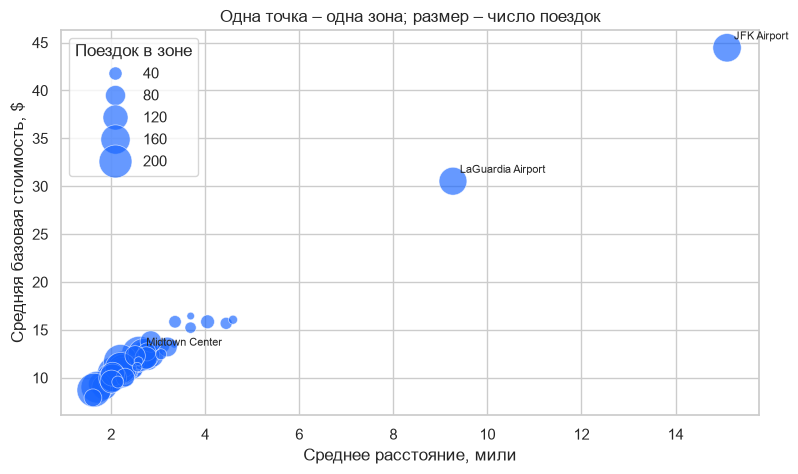

In [30]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(
    data=bubble_zones,
    x="mean_distance",
    y="mean_fare",
    size="trips",
    sizes=(30, 650),
    alpha=0.65,
    color="#1463FF",
    ax=ax,
)
for row in bubble_zones.loc[bubble_zones["pickup_zone"].isin(ZONE_ORDER)].itertuples():
    ax.annotate(
        row.pickup_zone,
        (row.mean_distance, row.mean_fare),
        xytext=(5, 6),
        textcoords="offset points",
        fontsize=8,
    )

ax.set(
    xlabel="Среднее расстояние, мили",
    ylabel="Средняя базовая стоимость, $",
    title="Одна точка – одна зона; размер – число поездок",
)
ax.legend(title="Поездок в зоне")

plt.show()

Связь средних по зонам не равна связи отдельных поездок: агрегация изменила смысл точек.

### **Число и цветовая шкала.**

До этого цвет различал категории. Теперь передадим им величину: сколько поездок находится рядом на плоскости.

| Что кодируем | Палитра | Пример |
| --- | --- | --- |
| Категории без порядка | Различимые оттенки | Тип такси |
| Величину от меньшего к большему | Последовательная (`sequential`) | Количество поездок |
| Отклонение от значимого центра | Расходящаяся (`diverging`) | Изменение относительно нуля |

`cmap` выбирает числовую палитру. Для следующего графика создадим переход от голубого к тёмно-синему через `LinearSegmentedColormap.from_list`: чем больше значение, тем темнее оттенок. Голубое начало шкалы позволит различить редкие наблюдения на белом фоне. `fig.colorbar` добавит числовую легенду.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #ef4444; background-color: #fef2f2; color: #991b1b;">
<strong>Антипаттерн: радуга для упорядоченных чисел.</strong><br>У радужной палитры скачки светлоты создают ложные границы, а порядок оттенков неочевиден. Последовательная шкала светлоты лучше передаёт рост величины; расходящаяся нужна лишь при содержательном центре.<br><a href="https://seaborn.pydata.org/tutorial/color_palettes.html"><code>Seaborn</code>: выбор палитры</a>
</div>

### **Шестиугольная гистограмма (`hexbin plot`).**

Если даже прозрачность не помогает, разобьём плоскость на шестиугольные ячейки и посчитаем точки внутри каждой. **`Hexbin`** показывает концентрацию пар значений, сохраняя обе числовые оси. `gridsize` задаёт подробность сетки, `mincnt=1` оставляет только непустые ячейки. Вернёмся ко всем поездкам.

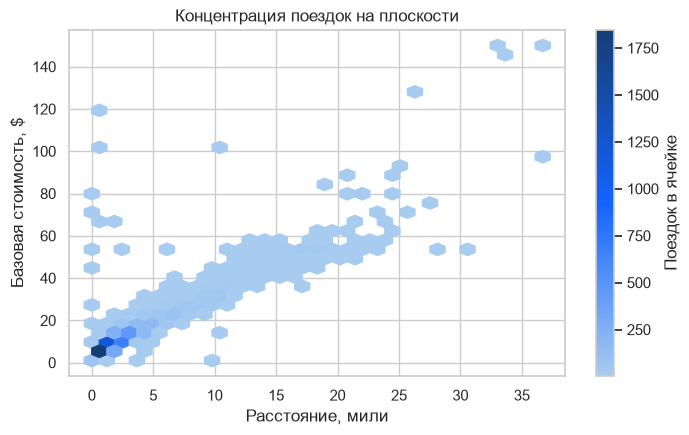

In [31]:
from matplotlib.colors import LinearSegmentedColormap

hexbin_cmap = LinearSegmentedColormap.from_list(
    "light_blue_to_dark", ["#A8CCF0", "#1463FF", "#153E75"]
)

fig, ax = plt.subplots(figsize=(8, 4.5))
hexagons = ax.hexbin(
    taxi["distance"],
    taxi["fare"],
    gridsize=30,
    mincnt=1,
    cmap=hexbin_cmap,
)
fig.patch.set_facecolor("white")
ax.set_facecolor("white")
fig.colorbar(hexagons, ax=ax, label="Поездок в ячейке")

ax.set(
    xlabel="Расстояние, мили",
    ylabel="Базовая стоимость, $",
    title="Концентрация поездок на плоскости",
)

plt.show()

`Hexbin` объединяет наблюдения в ячейках: отдельные поездки теряются, зато видны плотные области. Как у гистограммы, размер ячейки определяет детализацию. Голубые шестиугольники содержат мало поездок; пустые ячейки не нарисованы и остаются белыми.

В правой панели схемы в начале раздела к точкам добавлены **маргинальные распределения** (`marginal distributions`): сверху распределение `x`, справа – `y`. Они показывают каждую величину отдельно, а точки между ними – совместную связь. Отдельно строить его здесь не будем; для этого подходит [`sns.jointplot`](https://seaborn.pydata.org/generated/seaborn.jointplot.html).

---

## **Временной ряд и линейный график (`line chart`).**

Линия показывает изменение показателя, заливка подчёркивает его уровень. Накопление раскрывает состав общей суммы, а несколько линий позволяют сравнить ряды. Начнём с одной линии.

<div>
<a href="../../Other/images/06_line_charts.png"><img src="../../Other/images/06_line_charts.png" width="1100" style="max-width: 100%; height: auto;" alt="Линейные графики: одна линия, область под линией, области с накоплением и несколько линий"></a>
</div>

**Как меняется число поездок по дням?** Временной ряд – значения в порядке времени. Линейный график (`line chart`) показывает их изменение: соседство дат придаёт соединяющей линии смысл.

Выберем март и сгруппируем посадки по дням. Исходные часы записаны без пояса; используем их календарные даты.

In [32]:
taxi["pickup"] = pd.to_datetime(taxi["pickup"], format="%Y-%m-%d %H:%M:%S")

in_march = taxi["pickup"].ge("2019-03-01") & taxi["pickup"].lt("2019-04-01")
march = taxi.loc[in_march].copy()
daily = march.groupby(march["pickup"].dt.floor("D")).size()

# Полная сетка сохранит пропуски, если для какого-то дня нет записей.
days = pd.date_range("2019-03-01", "2019-03-31", freq="D")
daily = daily.reindex(days)
print("Дней без наблюдений:", daily.isna().sum())

Дней без наблюдений: 0


Единственную поездку за 28 февраля исключили выбором марта. `date_range` задаёт дневную сетку, `reindex` добавит `NaN` для дат без записей. `ax.plot` соединяет точки в переданном порядке, поэтому даты должны быть отсортированы.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #ef4444; background-color: #fef2f2; color: #991b1b;">
<strong>Антипаттерн: скрываем пропуск линией.</strong><br>Если убрать дату без измерения, линия соединит соседние известные точки и скроет пробел. На полной временной сетке <code>NaN</code> разрывает линию. Ноль допустим, только если известно, что значение действительно нулевое.<br><a href="https://matplotlib.org/stable/gallery/lines_bars_and_markers/masked_demo.html"><code>Matplotlib</code>: пропуски в линии</a>
</div>

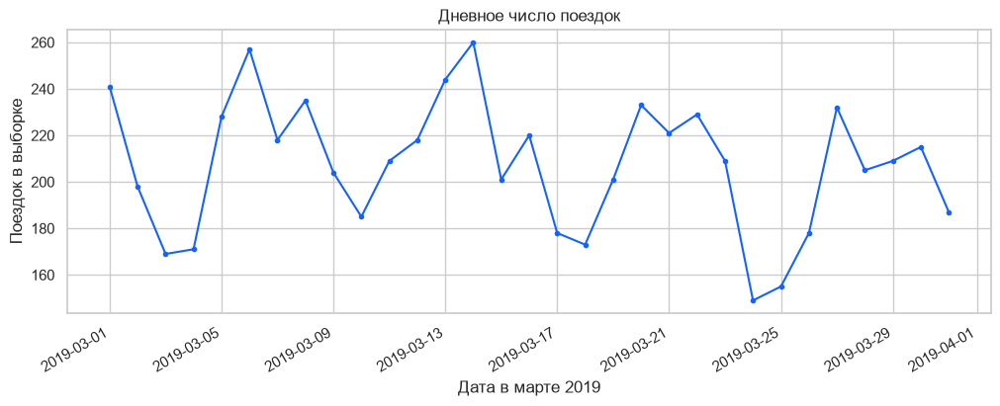

In [33]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.plot(daily.index, daily.values, marker="o", markersize=3, color="#1463FF")

ax.set(
    xlabel="Дата в марте 2019", ylabel="Поездок в выборке", title="Дневное число поездок"
)
fig.autofmt_xdate()

plt.show()

### **Агрегация и сглаживание.**

`resample("W-SUN")` объединяет дни в недели с окончанием в воскресенье. Первая содержит лишь три дня марта: её сумму нельзя напрямую сравнивать с семидневной. Оставим недели с семью наблюдаемыми днями.

In [34]:
weekly = daily.resample("W-SUN").agg(["sum", "count"])
full_weeks = weekly.loc[weekly["count"].eq(7), "sum"]
weekly

,sum,count
2019-03-03,608,3
2019-03-10,1498,7
2019-03-17,1530,7
2019-03-24,1415,7
2019-03-31,1381,7


`rolling(7, min_periods=7).mean()` усредняет текущую и шесть предыдущих строк. На нашей дневной сетке это семь дней; первые шесть результатов будут пропусками.

Слева построим две линии (`multi-line chart`): дневные значения и сглаживание. Справа покажем суммы за полные недели столбцами (`bar chart`). Это разные показатели: поездки за день и за неделю.

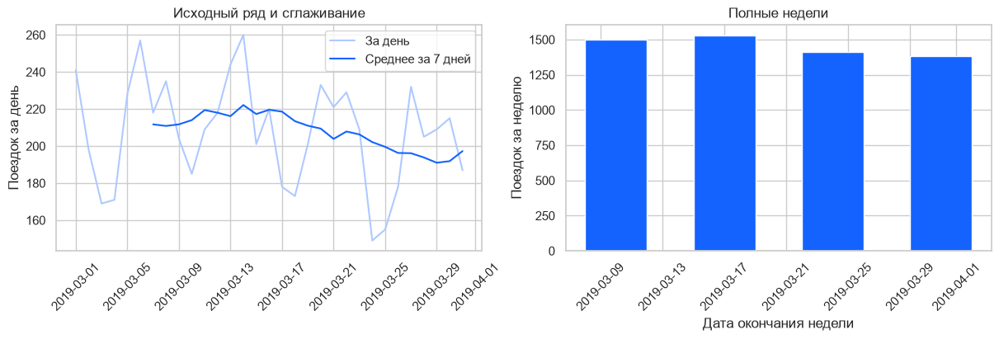

In [35]:
smoothed = daily.rolling(7, min_periods=7).mean()

fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout="constrained")
axes[0].plot(daily.index, daily, color="#AFC9FF", label="За день")
axes[0].plot(smoothed.index, smoothed, color="#1463FF", label="Среднее за 7 дней")
axes[0].set(title="Исходный ряд и сглаживание", ylabel="Поездок за день")
axes[0].legend()

axes[1].bar(full_weeks.index, full_weeks, width=4, color="#1463FF")
axes[1].set(
    title="Полные недели", ylabel="Поездок за неделю", xlabel="Дата окончания недели"
)
for ax in axes:
    ax.tick_params(axis="x", labelrotation=45)

plt.show()

Скользящее среднее сглаживает колебания и запаздывает при резком скачке. Оно не предсказывает будущие значения.

### **Сохраняем рисунок.**

`fig.savefig` сохраняет фигуру: `dpi` задаёт разрешение `PNG`, `bbox_inches="tight"` помогает вместить подписи. Для векторного изображения выбираем `.svg`.

Через `Path` создадим каталог результатов. Путь считается от папки ноутбука `Materials/Pro`; `mkdir(parents=True, exist_ok=True)` создаёт недостающие папки.

In [36]:
from pathlib import Path

OUTPUT = Path("outputs/06_visualisation")
OUTPUT.mkdir(parents=True, exist_ok=True)

fig.savefig(OUTPUT / "time_series.png", dpi=160, bbox_inches="tight")

### **Область под линией: `area chart`.**

Диаграмма областей (`area chart`) закрашивает пространство между линией и нулём, подчёркивая уровень показателя. Покажем тот же дневной ряд: `fill_between(x, 0, y)` заполнит область, `plot` обозначит верхнюю границу.

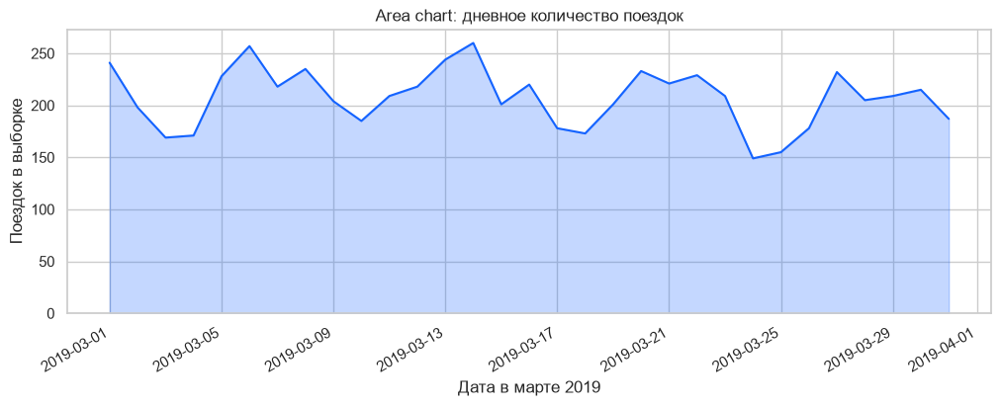

In [37]:
fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.fill_between(daily.index, 0, daily.values, color="#1463FF", alpha=0.25)
ax.plot(daily.index, daily.values, color="#1463FF")

ax.set(
    xlabel="Дата в марте 2019",
    ylabel="Поездок в выборке",
    title="Area chart: дневное количество поездок",
    ylim=(0, None),
)
fig.autofmt_xdate()

plt.show()

### **Области с накоплением: `stacked area chart`.**

**Как жёлтые и зелёные такси вносят вклад в общее количество?** Разложим дневной ряд по типам и сложим области через `stackplot`. Это `stacked area chart`.

**Толщина слоя**, а не высота его верхней границы, показывает количество поездок данного типа. Верхняя граница всей фигуры равна сумме.

Пропуск сочетания даты и типа заменим нулём: таких строк нет именно в нашей выборке.

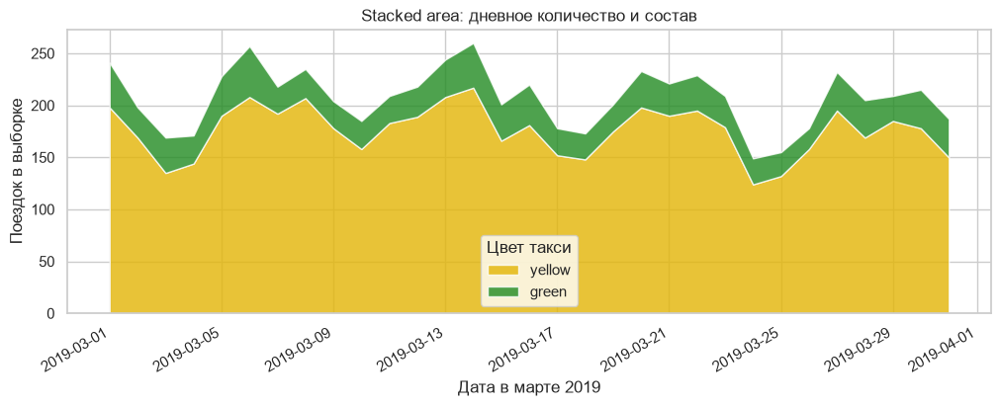

In [38]:
daily_by_color = (
    march.groupby([march["pickup"].dt.floor("D"), "color"]).size().unstack(fill_value=0)
)

fig, ax = plt.subplots(figsize=(10, 4), layout="constrained")
ax.stackplot(
    daily_by_color.index,
    daily_by_color["yellow"],
    daily_by_color["green"],
    labels=["yellow", "green"],
    colors=[TYPE_COLORS["yellow"], TYPE_COLORS["green"]],
    alpha=0.8,
)

ax.set(
    xlabel="Дата в марте 2019",
    ylabel="Поездок в выборке",
    title="Stacked area: дневное количество и состав",
)
ax.legend(title="Цвет такси")
fig.autofmt_xdate()

plt.show()

Отдельный вариант, без построения: если разделить значения слоёв на сумму за день и умножить на 100, получится нормированная диаграмма областей с накоплением (`100% stacked area chart`): верхняя граница станет постоянной, а толщины покажут доли.

Для сравнения колебаний отдельных групп удобнее линии или отдельные панели: у верхнего слоя накопления постоянно меняется основание.

### **Полярный график (`polar plot`): суточный профиль.**

Круговая компоновка помогает показать повторяющийся цикл. Для нашего примера возьмём часы суток; остальные варианты на схеме сопоставим словами после построения, без отдельных примеров кода.

<div>
<a href="../../Other/images/06_polar_charts.png"><img src="../../Other/images/06_polar_charts.png" width="1100" style="max-width: 100%; height: auto;" alt="Круговые компоновки: полярная линия, radar chart, радиальная тепловая карта и секторная диаграмма"></a>
</div>

**В какие часы чаще начинаются поездки?** Объединим одинаковые часы разных дней. Получится суточный профиль, а не последовательность событий.

Полярный график кодирует час углом, количество – расстоянием от центра. Он подчёркивает цикл: после 23 идёт 0. `subplot_kw` задаёт полярную проекцию; полный круг равен `2 * pi` радиан. Повторим первое значение в конце, чтобы замкнуть линию.

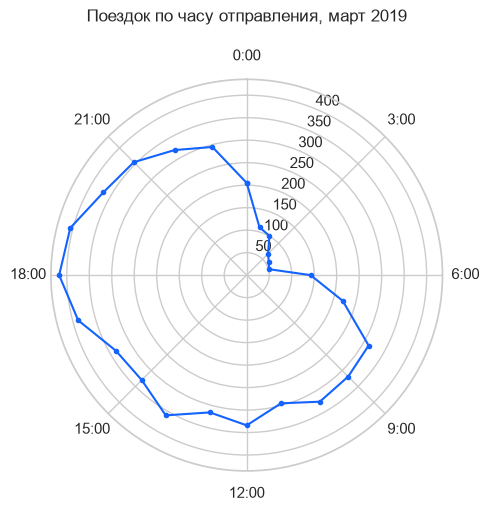

In [39]:
import numpy as np

hourly = march.groupby(march["pickup"].dt.hour).size().reindex(range(24), fill_value=0)
angles = np.arange(25) / 24 * 2 * np.pi
# Повторяем час 0 в конце круга.
closed_counts = np.r_[hourly.to_numpy(), hourly.iloc[0]]

fig, ax = plt.subplots(
    figsize=(6, 5), subplot_kw={"projection": "polar"}, layout="constrained"
)
ax.plot(angles, closed_counts, color="#1463FF", marker="o", markersize=3)
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_xticks(angles[:-1:3], [f"{hour % 24}:00" for hour in range(0, 24, 3)])
ax.set_ylim(bottom=0)

ax.set_title("Поездок по часу отправления, март 2019", pad=20)

plt.show()

Ноль часов сверху, направление – по часовой стрелке. Для точного сравнения двух часов столбцы проще; полярная форма полезна для соседства начала и конца цикла. Профиль одного месяца ещё не доказывает устойчивую сезонность.

Круговая компоновка используется и для других задач:

- Лепестковая диаграмма ([`radar chart`](https://plotly.com/python/radar-chart/)): лучи обозначают разные признаки, например оценки нескольких навыков. Их шкалы нужно согласовать.
- Радиальная тепловая карта (`radial heatmap`): значения передаются цветом ячеек в кольцах.
- Полярная секторная диаграмма (`rose chart`, диаграмма Найтингейл): величины распределены по угловым интервалам. Этот вариант показан справа на схеме.

На схеме углы указаны в градусах, ноль находится справа. В нашем суточном профиле мы заменили градусы часами и перенесли начало наверх. Для секторных графиков отдельно уточняют, кодируется ли значение радиусом или площадью: эти шкалы различаются.

---

## **Матрица направлений.**

**Куда направляются поездки из каждого района?** Сгруппируем по району посадки и высадки. Одна ячейка матрицы – число поездок с указанным началом и концом. Здесь исключаем записи с неизвестным концом или началом и сообщаем их число.

In [40]:
known_routes = taxi.dropna(subset=["pickup_borough", "dropoff_borough"])
print("Поездок без полного направления:", len(taxi) - len(known_routes))
routes = known_routes.groupby(["pickup_borough", "dropoff_borough"]).size()
boroughs = sorted(
    set(known_routes["pickup_borough"]) | set(known_routes["dropoff_borough"])
)
route_matrix = routes.unstack(fill_value=0).reindex(
    index=boroughs, columns=boroughs, fill_value=0
)
route_matrix

Поездок без полного направления: 50


dropoff_borough,Bronx,Brooklyn,Manhattan,Queens,Staten Island
pickup_borough,,,,,
Bronx,66,4,25,4,0
Brooklyn,5,282,67,26,0
Manhattan,55,153,4885,163,2
Queens,11,62,224,349,0
Staten Island,0,0,0,0,0


### **Тепловая карта (`heatmap`).**

На схеме показаны четыре представления:

- Тепловая карта (`heatmap`) – значение ячейки передаётся цветом.
- Тепловая карта с подписями (`annotated heatmap`) – цвет дополнен числами. Именно её построим ниже.
- Географическая тепловая карта (`geographic heatmap`) – концентрация точек на местности. Оставим как обзор: в нашем датасете нет координат отдельных посадок. Позже построим карту территорий.
- Древовидная карта ([`treemap`](https://plotly.com/python/treemaps/)) – состав целого через площади прямоугольников. Это отдельный тип графика, не тепловая карта; здесь он только для сравнения.

<div>
<a href="../../Other/images/06_heatmap_charts.png"><img src="../../Other/images/06_heatmap_charts.png" width="1100" style="max-width: 100%; height: auto;" alt="Матрица с цветом, матрица с подписями, географическая концентрация точек и treemap"></a>
</div>

Тепловая карта (`heatmap`) применяет знакомую числовую палитру к ячейкам матрицы. Она помогает увидеть сильные направления, диагональ и редкие сочетания.

`sns.heatmap` получает готовую таблицу. `annot=True` добавляет значения в ячейки, `fmt="d"` выводит целые количества, `cmap="Blues"` задаёт шкалу. Через `cbar_kws` подпишем числовую легенду справа.

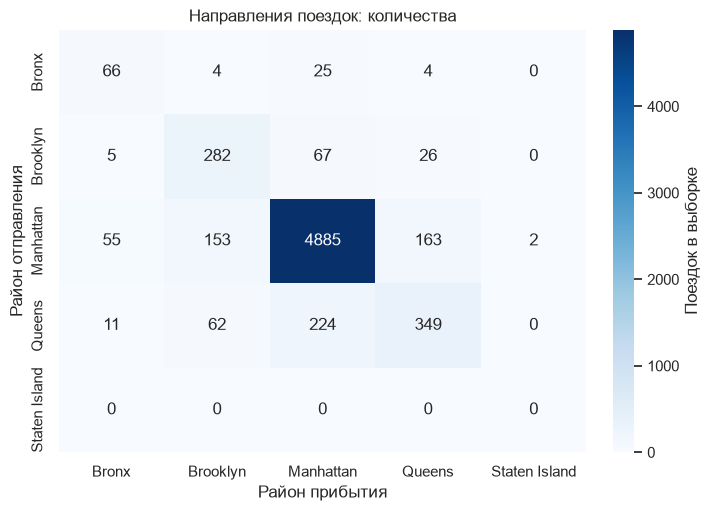

In [41]:
fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
sns.heatmap(
    route_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    ax=ax,
    cbar_kws={"label": "Поездок в выборке"},
)

ax.set(
    xlabel="Район прибытия",
    ylabel="Район отправления",
    title="Направления поездок: количества",
)

plt.show()

Manhattan доминирует по количеству записей. Чтобы сравнить направления внутри каждого района, нормируем строки на их суммы. Получится **нормированная по строкам тепловая карта** (`row-normalized heatmap`). Теперь вопрос звучит «какая доля поездок из этого района заканчивается в каждом другом?», а не «какой поток больше?»

В выборке могут быть прибытия в район без единой посадки из него. Для такой строки сумма равна нулю, и доли не определены: оставим пропуски, а не будем изображать нулевые проценты.

Для процентов зададим общие границы шкалы `vmin=0`, `vmax=100`, а `fmt=".1f"` оставит один знак после точки. Так один оттенок будет соответствовать одной доле во всей матрице.

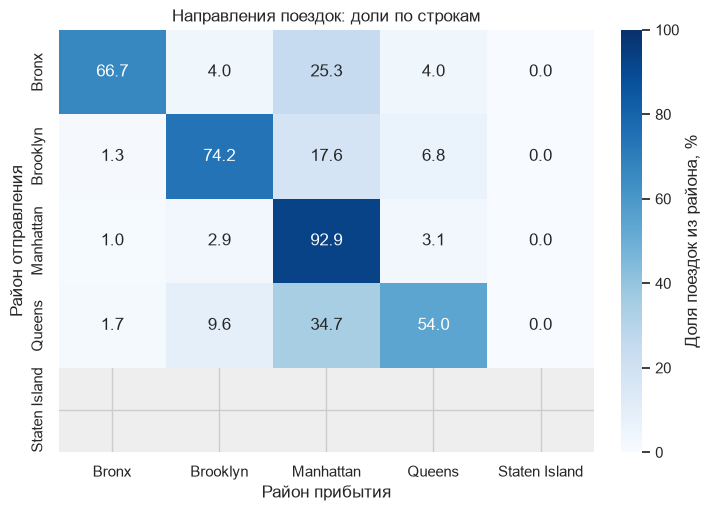

In [42]:
# Из района без посадок нельзя вычислить доли направлений.
departures_per_borough = route_matrix.sum(axis=1).replace(0, float("nan"))
route_share = route_matrix.div(departures_per_borough, axis=0) * 100

fig, ax = plt.subplots(figsize=(7, 5), layout="constrained")
ax.set_facecolor("#EEEEEE")
sns.heatmap(
    route_share,
    annot=True,
    fmt=".1f",
    cmap="Blues",
    vmin=0,
    vmax=100,
    ax=ax,
    cbar_kws={"label": "Доля поездок из района, %"},
)

ax.set(
    xlabel="Район прибытия",
    ylabel="Район отправления",
    title="Направления поездок: доли по строкам",
)

plt.show()

Серая строка без чисел означает, что доли не определены: посадок из этого района в выборке нет.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #3b82f6; background-color: #eff6ff; color: #1e40af;">
<strong>Приём: фиксируем цветовую шкалу.</strong><br>Сравнивая несколько матриц одного показателя, задаём общие <code>vmin</code> и <code>vmax</code>. При автоматическом подборе границ одинаково тёмные ячейки в разных панелях могут обозначать разные значения.
</div>

---

### **Корреляционная тепловая карта (`correlation heatmap`).**

**Какие числовые признаки меняются вместе?** В `heatmap` можно показать не только количества, но и корреляции. **Корреляция Пирсона** (`Pearson correlation`) измеряет линейную связь двух величин: значения близкие к `+1` означают согласованный рост, к `-1` – рост одной при снижении другой. Значение около `0` означает слабую линейную связь, но не исключает нелинейную.

`corr(method="pearson")` вычислит коэффициент для каждой пары столбцов. Строки и столбцы матрицы – признаки; диагональ равна 1, две половины симметричны. При пропусках `corr` использует заполненные пары наблюдений.

Ноль здесь имеет смысл, поэтому зададим расходящуюся шкалу: серый для отрицательных значений, белый для нуля, синий для положительных. Знакомый по `hexbin` метод `LinearSegmentedColormap.from_list` создаст переходы между этими цветами. Фиксируем диапазон от `-1` до `1`; `center=0` задаёт центр шкалы, `square=True` делает ячейки квадратными.

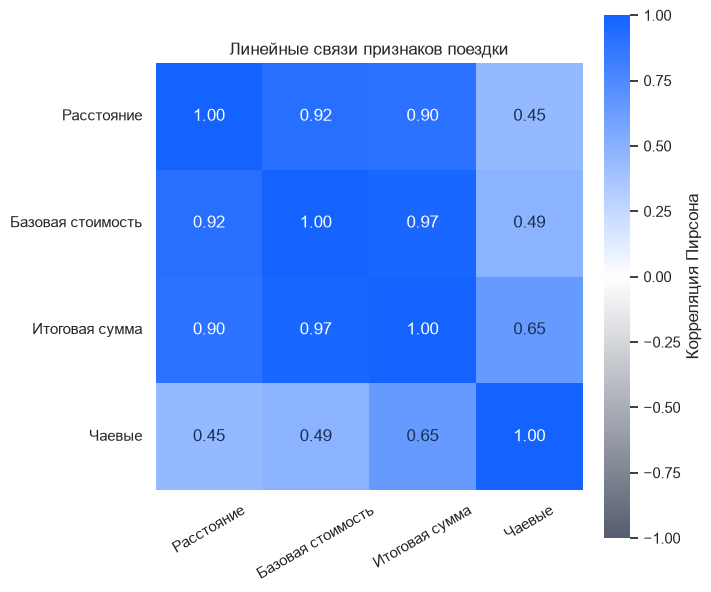

In [43]:
correlation_cmap = LinearSegmentedColormap.from_list(
    "gray_white_blue", ["#555D6E", "#FFFFFF", "#1463FF"]
)

correlations = taxi[["distance", "fare", "total", "tip"]].corr(method="pearson")
correlation_labels = ["Расстояние", "Базовая стоимость", "Итоговая сумма", "Чаевые"]

fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
sns.heatmap(
    correlations,
    annot=True,
    fmt=".2f",
    cmap=correlation_cmap,
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    xticklabels=correlation_labels,
    yticklabels=correlation_labels,
    cbar_kws={"label": "Корреляция Пирсона"},
    ax=ax,
)

# На светлых ячейках тёмные числа читаются лучше.
for label, value in zip(ax.texts, correlations.to_numpy().ravel()):
    label.set_color("white" if abs(value) > 0.75 else "#173052")

ax.set_title("Линейные связи признаков поездки")
ax.tick_params(axis="x", labelrotation=30)
ax.tick_params(axis="y", labelrotation=0)
plt.show()

`fare` и `total` сильно связаны, но базовая стоимость уже входит в итоговую сумму. Высокий коэффициент не доказывает причинность и не объясняет устройство тарифа. Для интересующей пары возвращаемся к `scatter plot`: он покажет форму связи и отдельные выбросы.

---

## **Интерактивные графики.**

На `scatter plot` были необычные точки. Теперь хочется узнать, какие поездки за ними стоят. **`Plotly`** добавляет подсказки, масштабирование и управление группами через легенду.

Высокоуровневый интерфейс `plotly.express` принимает таблицу и имена столбцов. `color` задаёт группировку, `hover_data` – дополнительные поля при наведении. Полученный `Figure` содержит данные графика и оформление.

In [44]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "notebook"
interactive_scatter = px.scatter(
    taxi,
    x="distance",
    y="fare",
    color="color",
    opacity=0.45,
    color_discrete_map=TYPE_COLORS,
    hover_data=["pickup_zone", "dropoff_zone", "payment"],
    labels={
        "distance": "Расстояние, мили",
        "fare": "Базовая стоимость, $",
        "color": "Цвет такси",
    },
    title="Расстояние и стоимость: детали отдельных поездок",
)
interactive_scatter.update_layout(template="plotly_white", height=480)
interactive_scatter.show()

Наведение раскрывает детали. Выделение области приближает её, двойной щелчок возвращает масштаб. Щелчок по легенде скрывает или показывает группу.

`update_layout` меняет оформление, не пересчитывая данные. Сохраним график отдельно: `include_plotlyjs="directory"` положит библиотеку `JavaScript` рядом с `HTML`. Для передачи такого файла нужно сохранить рядом и `plotly.min.js`.

In [45]:
interactive_scatter.write_html(OUTPUT / "scatter.html", include_plotlyjs="directory")

### **Иерархическая кольцевая диаграмма (`sunburst chart`).**

Рейтинг показал самые частые зоны, но скрыл их вложенность. Рассмотрим **район, внутри него зону, внутри зоны способ оплаты**. Это дерево группировки: каждый следующий уровень уточняет предыдущий.

`Sunburst` изображает уровни концентрическими кольцами. Размер сектора зависит от количества поездок; щелчок по сектору позволяет погрузиться в ветвь. Сначала подготовим именно эти количества. Пропуски оплаты обозначим явно, а записи без района или зоны вынесем за пределы этой иерархии с подсчётом исключений.

In [46]:
hierarchy_trips = taxi.dropna(subset=["pickup_borough", "pickup_zone"]).copy()
hierarchy_trips["payment"] = hierarchy_trips["payment"].fillna("Не указана")
print("Поездок без района или зоны:", len(taxi) - len(hierarchy_trips))
hierarchy = (
    hierarchy_trips.groupby(["pickup_borough", "pickup_zone", "payment"])
    .size()
    .rename("trips")
    .reset_index()
)
hierarchy.head()

Поездок без района или зоны: 26


,pickup_borough,pickup_zone,payment,trips
0,Bronx,Allerton/Pelham Gardens,credit card,2
1,Bronx,Bedford Park,credit card,1
2,Bronx,Belmont,cash,2
3,Bronx,Belmont,credit card,1
4,Bronx,Bronx Park,credit card,1


`path` перечисляет уровни от общего к частному, `values` задаёт вес конечных групп. Родительские значения получаются суммированием. Укажем в подсказке абсолютное число и долю внутри родителя: для зоны это доля в районе, для оплаты – доля в зоне.

Закрепим цвета районов в `BOROUGH_COLORS`: их же используем позже в `Sankey` и графе направлений. В карте зон цвет будет иметь другой смысл – числовое количество посадок, указанное на шкале.

In [47]:
BOROUGH_COLORS = {
    "Bronx": "#153EAB",
    "Brooklyn": "#6C9EFF",
    "Manhattan": "#1463FF",
    "Queens": "#AFC9FF",
    "Staten Island": "#D6E4FF",
}
sunburst = px.sunburst(
    hierarchy,
    path=["pickup_borough", "pickup_zone", "payment"],
    values="trips",
    color="pickup_borough",
    color_discrete_map=BOROUGH_COLORS,
    title="Где начинаются поездки и как их оплачивают",
)
sunburst.update_traces(
    hovertemplate="%{label}<br>Поездок: %{value}<br>Доля внутри родителя: %{percentParent:.1%}<extra></extra>",
    maxdepth=2,
)
sunburst.update_layout(height=600, margin=dict(t=60, l=10, r=10, b=10))
sunburst.show()

sunburst.write_html(OUTPUT / "sunburst.html", include_plotlyjs="directory")

`maxdepth=2` ограничивает число одновременно видимых уровней: глубокие категории открываем щелчком. Чтобы вернуться выше, используем центральный сектор.

Это хороший способ исследовать вложенность. Для точного сравнения двух близких значений удобнее столбцы: углы и площади читаются хуже длины. При множестве зон интерактивность помогает, но не превращает все подписи в читаемые одновременно.

### **Трёхмерная диаграмма рассеяния (`3D scatter plot`).**

Добавим длительность к расстоянию и стоимости. Преобразуем `dropoff` в дату, вычтем уже подготовленный `pickup` и переведём секунды в минуты через `.dt.total_seconds() / 60`. Каждая точка теперь имеет три координаты; сцену можно вращать. Длительность здесь вычислена по записанным местным часам, поэтому возле перевода часов она не гарантирует физически прошедший интервал.

Для этой демонстрации оставим положительные расстояния и длительности, явно посчитав исключённые строки. Исходную таблицу сохраним.

In [48]:
taxi["dropoff"] = pd.to_datetime(taxi["dropoff"], format="%Y-%m-%d %H:%M:%S")
taxi["duration_min"] = (taxi["dropoff"] - taxi["pickup"]).dt.total_seconds() / 60

trips_3d = taxi.loc[taxi["distance"].gt(0) & taxi["duration_min"].gt(0)].copy()
print("Исключено только из 3D-примера:", len(taxi) - len(trips_3d))
fig_3d = px.scatter_3d(
    trips_3d,
    x="distance",
    y="duration_min",
    z="fare",
    color="color",
    color_discrete_map=TYPE_COLORS,
    opacity=0.35,
    labels={
        "distance": "Мили",
        "duration_min": "Минуты",
        "fare": "Стоимость, $",
        "color": "Цвет такси",
    },
    title="Расстояние, длительность и стоимость",
)
fig_3d.update_traces(marker_size=2)
fig_3d.update_layout(height=520)
fig_3d.show()

fig_3d.write_html(OUTPUT / "scatter_3d.html", include_plotlyjs="directory")

Исключено только из 3D-примера: 51


3D позволяет исследовать три величины, меняя ракурс. На статическом рисунке перекрытия и перспектива затрудняют чтение; тогда лучше две плоские проекции. Декоративная глубина у обычных столбцов не добавляет показателя.

---

## **Географические данные и `GeoPandas`.**

**Где находятся зоны из нашего рейтинга?** По одному названию района библиотека не знает его границ. Для карты сначала нужны **геоданные**: координаты точек или контуры территорий. Их берут из своего источника либо из географического справочника.

Разделим три составляющие:

| Составляющая | Что даёт | В нашем примере |
| --- | --- | --- |
| Геометрия | Где находится объект и какую имеет форму | Границы зон такси |
| Показатель | Что показываем цветом или размером | Число посадок в зоне |
| Подложка | Фон для ориентации: улицы, реки, подписи | `OpenStreetMap` в интерактивных примерах |

Подложка не содержит наших поездок и не заменяет границы зон. Она необязательна: сначала нарисуем сами контуры, затем добавим улицы на интерактивной карте. Готовую картинку города скачивать заранее не требуется.

В `CSV` нет координат посадки. Возьмём границы из подготовленного файла [TLC](https://www.nyc.gov/site/tlc/about/tlc-trip-record-data.page) в формате `GeoJSON`: он хранит геометрию и свойства объектов. `Polygon` описывает многоугольник, `MultiPolygon` – несколько частей одной зоны.

`GeoPandas` расширяет `Pandas`: в `GeoDataFrame` специальный столбец `geometry` хранит формы объектов. Это `GeoSeries`; остальные свойства можно фильтровать и соединять как обычную таблицу. Файл `Other/data/visualisation/taxi_zones.geojson` уже объединён и упрощён для урока.

In [49]:
import geopandas as gpd

DATA = Path("../../Other/data/visualisation")

zones_gdf = gpd.read_file(DATA / "taxi_zones.geojson")
print("Зон в справочнике:", len(zones_gdf))
zones_gdf[["borough", "zone", "zone_id", "geometry"]].head()

Зон в справочнике: 260


,borough,zone,zone_id,geometry
0,Bronx,Allerton/Pelham Gardens,zone_0,"POLYGON ((-73.8486 40.87167, -73.83578 40.8650..."
1,Bronx,Bedford Park,zone_1,"POLYGON ((-73.88147 40.86857, -73.88683 40.865..."
2,Bronx,Belmont,zone_2,"POLYGON ((-73.88387 40.86429, -73.88201 40.862..."
3,Bronx,Bronx Park,zone_3,"POLYGON ((-73.87094 40.85727, -73.86955 40.857..."
4,Bronx,Bronxdale,zone_4,"POLYGON ((-73.85664 40.85812, -73.86759 40.857..."


### **Система координат: `CRS`.**

Числа в геометрии нужно уметь интерпретировать: это могут быть градусы долготы и широты или координаты на плоскости в метрах. **`CRS`** (`coordinate reference system`) задаёт систему координат; `GeoPandas` хранит её в `.crs`.

У нашего `GeoJSON` система `WGS 84`, обозначаемая `EPSG:4326`. Координаты записаны как **долгота, широта**, в градусах. Проверим систему и типы геометрий перед построением.

In [50]:
print("Система координат:", zones_gdf.crs)
zones_gdf.geometry.geom_type.value_counts()

Система координат: EPSG:4326


Polygon         235
MultiPolygon     25
Name: count, dtype: int64

Для статического рисунка переведём границы в подходящую для Нью-Йорка плоскую систему `UTM` с координатами в метрах. `estimate_utm_crs()` подбирает местную зону `UTM` по расположению данных, а `to_crs()` пересчитывает координаты. Для небольшой территории города это удобный вариант.

Исходный `zones_gdf` сохраним в долготе и широте: он понадобится интерактивным картам.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #ef4444; background-color: #fef2f2; color: #991b1b;">
<strong>Антипаттерн: переименовываем <code>CRS</code> вместо преобразования.</strong><br><code>set_crs()</code> лишь описывает, в какой системе уже записаны координаты; числа не меняются. Для перехода из градусов в метры нужен <code>to_crs()</code>. Измерять площадь в градусах и подписывать результат как км² нельзя.<br><a href="https://geopandas.org/en/stable/docs/user_guide/projections.html"><code>GeoPandas</code>: задание и преобразование <code>CRS</code></a>
</div>

In [51]:
local_crs = zones_gdf.estimate_utm_crs()
zones_local = zones_gdf.to_crs(local_crs)
print("Система для статической карты:", zones_local.crs)

Система для статической карты: EPSG:32618


### **Границы и слои.**

Начнём без количества поездок: покажем зоны и выделим Манхэттен. Фильтрация через `.loc` работает как в `Pandas`. Два вызова `.plot(ax=ax)` рисуют слои в одной области: сначала все границы, затем выбранные зоны поверх них.

Синий здесь означает выбранный район, а не число посадок. Уберём координатные оси через `set_axis_off()`: сейчас важнее расположение территорий.

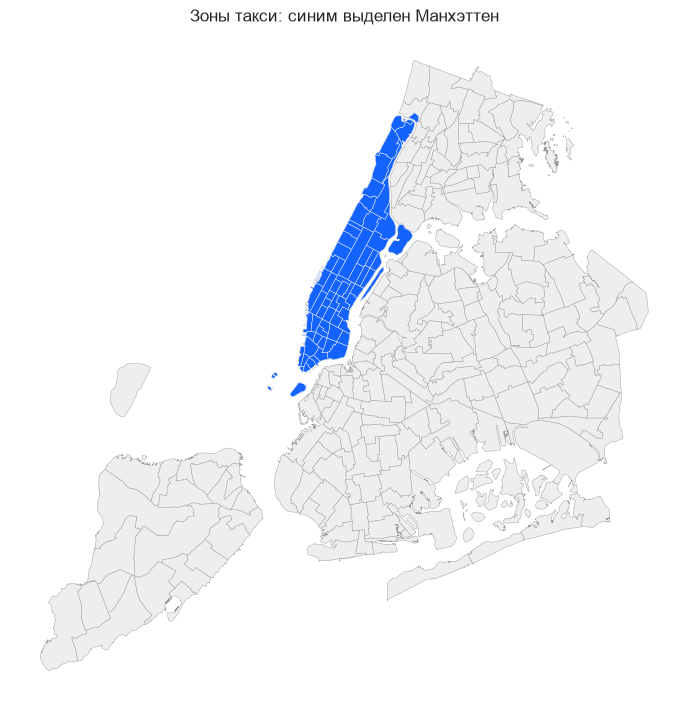

In [52]:
fig, ax = plt.subplots(figsize=(7, 7), layout="constrained")
zones_local.plot(ax=ax, color="#EEEEEE", edgecolor="#999999", linewidth=0.3)
zones_local.loc[zones_local["borough"].eq("Manhattan")].plot(
    ax=ax,
    color=BOROUGH_COLORS["Manhattan"],
    edgecolor="white",
    linewidth=0.3,
)

ax.set_title("Зоны такси: синим выделен Манхэттен")
ax.set_axis_off()

plt.show()

### **Количество поездок по зонам.**

Теперь присоединим к геометриям данные поездок. В реальных таблицах лучше соединять по стабильному идентификатору. В нашей выборке его нет: сопоставим **район и название зоны**, затем проверим результат.

Справочник содержит одну геометрию для каждой такой пары. `zone_id` – локальный ключ карты, не идентификатор исходной поездки. Для сопоставления строк поездок достаточно обычной таблицы свойств без геометрии.

In [53]:
zone_lookup = pd.DataFrame(zones_gdf[["borough", "zone", "zone_id"]])
zone_lookup.head()

,borough,zone,zone_id
0,Bronx,Allerton/Pelham Gardens,zone_0
1,Bronx,Bedford Park,zone_1
2,Bronx,Belmont,zone_2
3,Bronx,Bronx Park,zone_3
4,Bronx,Bronxdale,zone_4


Соединим поездки со справочником. `validate="many_to_one"` проверит, что каждой паре район/зона соответствует не больше одной строки справочника. `indicator=True` добавит признак успешности соединения: так увидим записи без подходящей зоны.

In [54]:
mapped_trips = taxi.merge(
    zone_lookup,
    left_on=["pickup_borough", "pickup_zone"],
    right_on=["borough", "zone"],
    how="left",
    validate="many_to_one",
    indicator=True,
)
print(mapped_trips["_merge"].value_counts())
mapped_trips.loc[
    mapped_trips["_merge"].eq("left_only"), ["pickup_borough", "pickup_zone"]
].value_counts(dropna=False).head()

_merge
both          6407
left_only       26
right_only       0
Name: count, dtype: int64


pickup_borough  pickup_zone
NaN             NaN            26
Name: count, dtype: int64

26 поездок не имеют района или зоны и не попадут на карту. Посчитаем только успешно сопоставленные поездки, затем присоединим количества к **`GeoDataFrame` с геометриями**.

Вызываем `.merge()` у геотаблицы слева, чтобы сохранить геометрию и `CRS` результата. `how="left"` оставит все территории, включая зоны без записей; у них `trips` будет пропуском. Отсутствие записей в выборке не означает отсутствие такси в городе.

In [55]:
map_counts = (
    mapped_trips.dropna(subset=["zone_id"]).groupby("zone_id").size().rename("trips")
)
zone_stats = zones_gdf.merge(
    map_counts.reset_index(), on="zone_id", how="left", validate="one_to_one"
)
zone_stats[["zone", "trips", "geometry"]].sort_values("trips", ascending=False).head()

,zone,trips,geometry
143,Midtown Center,230.0,"POLYGON ((-73.97124 40.76094, -73.97581 40.754..."
162,Upper East Side South,211.0,"POLYGON ((-73.95826 40.77297, -73.96658 40.761..."
149,Penn Station/Madison Sq West,210.0,"POLYGON ((-73.98777 40.74979, -73.99142 40.744..."
113,Clinton East,208.0,"POLYGON ((-73.98237 40.76739, -73.99163 40.754..."
144,Midtown East,198.0,"POLYGON ((-73.96657 40.76148, -73.97445 40.750..."


### **Картограмма в `GeoPandas`.**

**Картограмма (`choropleth`)** окрашивает территории по величине показателя. Она помогает увидеть пространственные скопления: соседствуют ли зоны с большим числом поездок?

`column="trips"` выбирает показатель, `cmap="Blues"` задаёт числовую шкалу, `legend=True` добавляет её на рисунок. `missing_kwds` отдельно оформляет зоны без записей: серый не входит в шкалу количества. Рисуем в уже выбранной местной проекции.

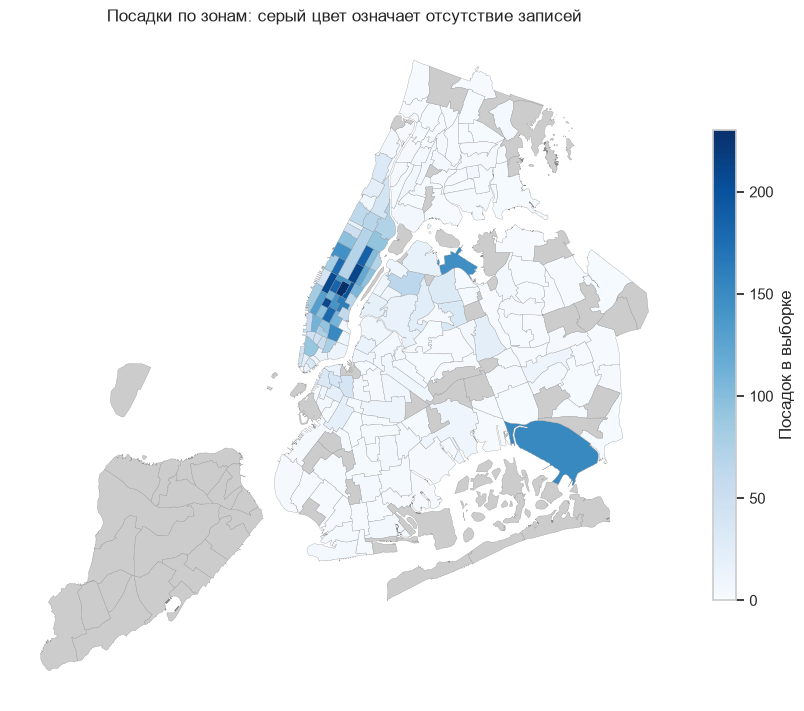

In [56]:
fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
zone_stats.to_crs(local_crs).plot(
    column="trips",
    cmap="Blues",
    vmin=0,
    vmax=zone_stats["trips"].max(),
    legend=True,
    legend_kwds={"label": "Посадок в выборке", "shrink": 0.7},
    missing_kwds={"color": "#CCCCCC", "label": "Нет записей"},
    edgecolor="#888888",
    linewidth=0.2,
    ax=ax,
)

ax.set_title("Посадки по зонам: серый цвет означает отсутствие записей")
ax.set_axis_off()

plt.show()

fig.savefig(OUTPUT / "geopandas_zones.png", dpi=160, bbox_inches="tight")

`GeoPandas` построил статическую карту без интернет-подложки. Для точного сравнения количеств используем столбцы; карта нужна для расположения зон.

Границы упрощены для отображения. Для измерения площади нужны исходные границы достаточной точности и подходящая проекция.

<div style="padding: 12px 16px; margin: 16px 0; border-radius: 6px; border-left: 4px solid #ef4444; background-color: #fef2f2; color: #991b1b;">
<strong>Антипаттерн: принимаем количество за интенсивность.</strong><br>Карта показывает записи по зонам, но не частоту посадок на единицу площади. Для этого нужен другой показатель, например поездки на км². Даже при одинаковой окраске большая территория визуально заметнее маленькой.
</div>

### **Подготовка интерактивной карты.**

Данные уже подготовлены: добавим подсказки и переведём геотаблицу в `GeoJSON` через `.to_json()`. `json.loads()` превращает `JSON`-текст в словарь `Python`. Используем `zone_stats` с координатами в `EPSG:4326`, а не его копию в метрах.

`drop_id=True` убирает лишний идентификатор, создаваемый из индекса. Для связи таблицы с геометрией у нас есть явное свойство `zone_id`. В `map_table` оставим обычные столбцы, без геометрии.

In [57]:
import json

# Для подсказки сохраняем отличие пропуска от нуля.
zone_stats["trips_label"] = zone_stats["trips"].map(
    lambda count: str(int(count)) if pd.notna(count) else "Нет записей"
)
zones = json.loads(zone_stats.to_json(drop_id=True))
map_table = pd.DataFrame(zone_stats.drop(columns="geometry"))

### **Интерактивная картограмма (`choropleth map`) в `Plotly`.**

**Хотим рассмотреть отдельные зоны и узнать их показатели.** В `Plotly` карта – ещё один график: передаём таблицу, выбираем числовой цвет и поля подсказки, как у `scatter`. Это удобно, когда анализ включает и карту, и обычные диаграммы.

`geojson` передаёт границы, `locations="zone_id"` – ключ из таблицы, `featureidkey="properties.zone_id"` – ключ геометрии. Объекты связываются по идентификатору, а не по порядку строк.

`color="trips"` задаёт числовую окраску. `map_style="open-street-map"` добавляет подложку улиц: её фрагменты загружаются при просмотре и масштабировании. Это отдельный слой, которому нужен интернет. `center` и `zoom` задают начальный вид; серый фоновый слой выделит зоны без записей.

In [58]:
plotly_map = px.choropleth_map(
    map_table.dropna(subset=["trips"]),
    geojson=zones,
    locations="zone_id",
    featureidkey="properties.zone_id",
    color="trips",
    color_continuous_scale="Blues",
    range_color=(0, map_table["trips"].max()),
    hover_name="zone",
    hover_data={"borough": True, "trips": True, "zone_id": False},
    labels={"borough": "Район", "trips": "Посадок в выборке"},
    map_style="open-street-map",
    center={"lat": 40.74, "lon": -73.95},
    zoom=9.5,
    opacity=0.85,
    title="Посадки по зонам Нью-Йорка",
    height=570,
)
plotly_map.update_layout(
    margin=dict(l=0, r=0, t=50, b=0),
    map_layers=[
        dict(
            source=zones, sourcetype="geojson", type="fill", color="#CCCCCC", below="traces"
        )
    ],
)
plotly_map.show()

plotly_map.write_html(OUTPUT / "plotly_zones.html", include_plotlyjs="directory")

Наведение показывает название зоны и количество посадок. Масштабирование помогает рассмотреть Манхэттен; рядом с легендой видна числовая шкала. Серый фон означает, что для зоны нет сопоставленных записей в этой выборке; он не входит в шкалу количеств.

Ниже – ориентиры для других задач, без дополнительных построений в этом уроке.

| Географический график `Plotly` | Когда нужен | Какие данные потребуются |
| --- | --- | --- |
| Картограмма (`choropleth map`), `choropleth_map` | Сравнить показатели территорий | Границы и ключ для соединения с показателем |
| Точечная карта (`scatter map`), `scatter_map` | Показать точки, например станции или магазины | Долгота и широта каждого места |
| Карта плотности (`density map`), `density_map` | Показать пространственную концентрацию точек | Координаты наблюдений; результат зависит от сглаживания |
| Карта линий (`line map`), `line_map` | Показать географический путь | Упорядоченные координаты пути |

В нашем `CSV` нет координат посадки. Границы зон позволяют построить картограмму, но не дают точные точки поездок. Соединение центров зон также не восстановит реальный маршрут машины.

<details>
<summary>Как открыть сохранённую карту</summary>

Карта работает в `Jupyter`. При открытии сохранённого `HTML` через `file://` некоторые браузеры не загружают геометрию: для фоновой обработки данных нужен `HTTP`. Из каталога ноутбука запустите:

```bash
python -m http.server 8000 --directory outputs/06_visualisation
```

Затем откройте [карту на localhost](http://localhost:8000/plotly_zones.html). Для подложки `OpenStreetMap` по-прежнему нужен интернет.

</details>

### **Картограмма и слои в `Folium`.**

**А если нужно по очереди включать посадки, границы районов и другие объекты?** В `Folium` начинаем с карты и добавляем независимые слои: области, маркеры, маршруты, всплывающие карточки. Такой подход удобен, например, для карты пунктов выдачи и зон доставки.

`Folium` создаёт из кода `Python` интерактивную карту `HTML`; её работу в браузере обеспечивает `Leaflet`. Нам не нужно писать `JavaScript`, чтобы добавить слои и переключатель.

На наших данных оставим слой количества посадок и добавим **отдельный слой границ районов**. Оставим пять районов из `BOROUGH_COLORS`: `dissolve(by="borough")` объединит геометрии их зон. Это контуры из справочника такси, а не отдельные административные границы. `LayerControl` позволит включать и выключать слои.

`Map` создаёт карту, `Choropleth` окрашивает зоны, `GeoJson` добавляет контуры, `GeoJsonTooltip` – подсказки. `key_on` связывает геометрию со столбцом `zone_id`. У `location` порядок **широта, долгота**, внутри `GeoJSON` – **долгота, широта**.

In [59]:
import folium

# Пять районов города; служебную группу EWR не включаем в этот слой.
city_zones = zones_gdf.loc[zones_gdf["borough"].isin(BOROUGH_COLORS)]
borough_boundaries = (
    city_zones[["borough", "geometry"]].dissolve(by="borough").reset_index()
)

zone_map = folium.Map(location=[40.74, -73.95], zoom_start=10, tiles="OpenStreetMap")
choropleth = folium.Choropleth(
    geo_data=zones,
    data=map_table,
    columns=["zone_id", "trips"],
    key_on="feature.properties.zone_id",
    name="Посадки по зонам",
    fill_color="Blues",
    fill_opacity=0.8,
    line_opacity=0.25,
    nan_fill_color="#CCCCCC",
    legend_name="Посадок в выборке",
).add_to(zone_map)
folium.GeoJsonTooltip(
    fields=["borough", "zone", "trips_label"],
    aliases=["Район:", "Зона:", "Посадок в выборке:"],
).add_to(choropleth.geojson)

# Независимый слой можно отключить, не убирая окраску зон.
folium.GeoJson(
    borough_boundaries.to_json(drop_id=True),
    name="Границы районов",
    interactive=False,  # Контуры не перехватывают подсказки слоя посадок.
    style_function=lambda feature: {"color": "#333333", "weight": 2, "fill": False},
).add_to(zone_map)
folium.LayerControl(collapsed=False).add_to(zone_map)

zone_map.save(str(OUTPUT / "taxi_zones.html"))
zone_map

В переключателе можно скрыть посадки и оставить границы районов, затем включить оба слоя. Это пример **исследования слоёв карты**. В примере `Plotly` мы исследовали **показатель из таблицы** через цвет и наведение.

| Задача | С чего удобно начать |
| --- | --- |
| Быстро добавить карту показателя к графикам анализа | `Plotly`: знакомые `color`, `hover_data` и настройки фигуры |
| Собрать карту из переключаемых границ, маркеров и маршрутов | `Folium`: независимые слои и элементы управления картой |

Оба инструмента умеют подсказки, масштабирование и сохранение в `HTML`; это не их различие. Выбор зависит от того, строим ли мы прежде всего аналитический график или карту со слоями. Возможности пересекаются: дополнительные слои есть и у `Plotly`.

Границы взяты из отдельного справочника: сопоставление с поездками 2019 года не доказывает неизменность территорий во времени.

---

## **Диаграмма Санки (`Sankey diagram`): потоки между районами.**

Матрица направлений отвечала, сколько поездок связывает каждую пару районов. **Диаграмма Санки (`Sankey diagram`)** показывает те же потоки лентами: слева места отправления, справа места прибытия, ширина ленты пропорциональна количеству поездок.

Включим и поездки внутри района: Manhattan слева и Manhattan справа обозначают разные роли, поэтому между ними тоже есть поток. Используем уже рассчитанный `routes`, без строк с неизвестным районом.

Для этого графика возьмём `plotly.graph_objects`: `node` задаёт узлы, а `link` – индексы начала, конца и величины потоков. Узлы справа получат индексы после всех узлов слева.

In [60]:
import plotly.graph_objects as go

flows = routes.rename("trips").reset_index()
borough_index = {name: i for i, name in enumerate(boroughs)}
# Индексы правых узлов начинаются после всех левых.
flow_figure = go.Figure(
    go.Sankey(
        node={
            "label": [f"Из: {name}" for name in boroughs]
            + [f"В: {name}" for name in boroughs],
            "color": [BOROUGH_COLORS[name] for name in boroughs] * 2,
            "pad": 18,
            "thickness": 16,
        },
        link={
            "source": flows["pickup_borough"].map(borough_index),
            "target": flows["dropoff_borough"].map(borough_index) + len(boroughs),
            "value": flows["trips"],
            "color": "rgba(20, 99, 255, 0.22)",
        },
    )
)
flow_figure.update_layout(
    title="Из каких районов и в какие едут: ширина равна числу поездок", height=550
)
flow_figure.show()

flow_figure.write_html(OUTPUT / "flows.html", include_plotlyjs="directory")

`Sankey` подходит, когда важно увидеть объём и разветвление потоков. Небольшие потоки рядом с доминирующим могут стать почти незаметны: для точных значений возвращаемся к матрице или используем наведение.

Для сравнения, без отдельного построения: **хордовая диаграмма (`chord diagram`)** тоже изображает потоки, но размещает районы по окружности и связывает их лентами. Она удобна для компактного обзора связей между небольшим числом групп; много пересекающихся лент трудно читать. `Sankey` здесь яснее разделяет отправление и прибытие.

## **Сетевой граф (`network graph`).**

**Какие районы связаны поездками?** Представим их вершинами графа, направления – рёбрами, количество поездок – весами. Такой рисунок помогает увидеть основные связи и районы с малым числом направлений.

Та же модель подходит для переводов между счетами, зависимостей сервисов или поставок между складами. `NetworkX` позволяет не только рисовать граф, но и искать пути, компоненты связности и важные узлы. Например, в сети сервисов так изучают зависимости при сбое.

Возьмём межрайонные поездки: петли внутри района уже были видны на диагонали `heatmap`. Используем круговую раскладку, чтобы расположение узлов не воспринималось как география.

`font_color` получит словарь цветов подписей: белые на тёмных узлах и тёмные на светлых, чтобы названия оставались читаемыми.

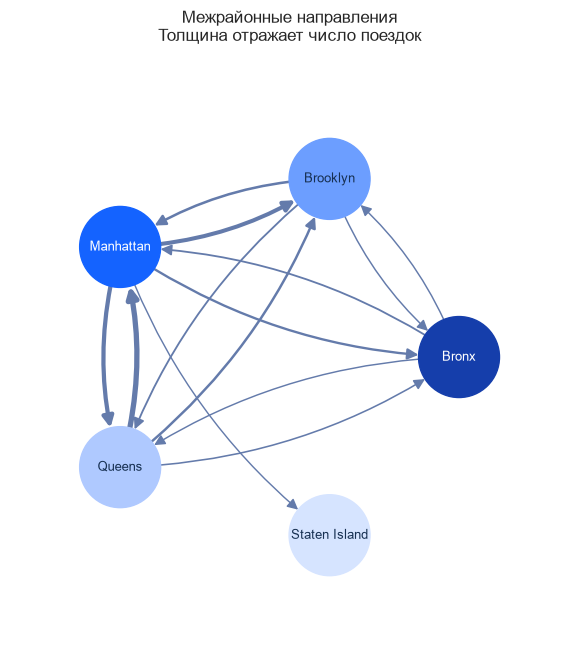

In [61]:
import networkx as nx

edges = routes.rename("trips").reset_index()
edges = edges.loc[edges["pickup_borough"].ne(edges["dropoff_borough"])]
graph = nx.from_pandas_edgelist(
    edges,
    source="pickup_borough",
    target="dropoff_borough",
    edge_attr="trips",
    create_using=nx.DiGraph(),
)
positions = nx.circular_layout(graph)
widths = [1 + graph[u][v]["trips"] / 80 for u, v in graph.edges]

label_colors = {
    name: "white" if name in {"Bronx", "Manhattan"} else "#173052"
    for name in graph
}

graph_fig, graph_ax = plt.subplots(figsize=(8, 6.5), layout="constrained")
nx.draw_networkx(
    graph,
    pos=positions,
    ax=graph_ax,
    width=widths,
    node_color=[BOROUGH_COLORS[name] for name in graph],
    node_size=3400,
    font_size=9,
    font_color=label_colors,
    edge_color="#647BAB",
    arrowsize=16,
    connectionstyle="arc3,rad=0.15",
)

# Автомасштаб учитывает центры узлов, но крупным кругам нужен запас по краям.
graph_ax.margins(0.25)
graph_ax.set_aspect("equal")
graph_ax.set_title("Межрайонные направления\nТолщина отражает число поездок", pad=16)
graph_ax.set_axis_off()
plt.show()

Наконечник показывает направление, дуги разводят встречные связи. Толщина помогает найти крупные потоки; точные значения читаем в матрице. Сотни узлов перегрузят такой рисунок: тогда выбирают подграф или объединяют узлы в группы.

### **Другие инструменты и задачи.**

У визуализации есть задачи за пределами обычных таблиц. Ниже – обзор инструментов без примеров кода: ссылки ведут к документации и демонстрациям.

| Данные | Что хотим увидеть | Инструмент |
| --- | --- | --- |
| Ряд или сводная таблица | Быстрый график прямо из результата расчёта | `pandas.plot` |
| Несколько связанных таблиц и графиков | Выделить наблюдения на одной панели и подсветить их на другой | [`Bokeh`](https://docs.bokeh.org/en/latest/docs/user_guide/interaction/linking.html) |
| Миллионы точек или траекторий | Показать плотность без отрисовки каждой точки | [`Datashader`](https://datashader.org/) |
| Зависимости задач и компонентов | Автоматически разместить схему со стрелками | [`Graphviz`](https://graphviz.org/) |
| Сеть пользователей или объектов | Перемещать вершины, исследовать связи в браузере | [`PyVis`](https://pyvis.readthedocs.io/en/latest/) |
| Пространственные сетки и объёмные данные | Исследовать поверхность, сечение или объём в 3D | [`PyVista`](https://docs.pyvista.org/) |
| Таблица с пропусками | Увидеть, какие поля часто отсутствуют вместе | [`missingno`](https://github.com/ResidentMario/missingno) |
| Текст и частоты слов | Сделать обзор частых слов облаком; для точного сравнения лучше столбцы | [`wordcloud`](https://amueller.github.io/word_cloud/) |

## **Дополнительное чтение.**

- [ONS: руководство по визуализации](https://service-manual.ons.gov.uk/data-visualisation) – выбор графика, шкал и цвета.
- [Осторожно, ось обрезана](https://sysblok.ru/infographics/ostorozhno-os-obrezana-kak-nas-obmanyvajut-grafiki/) – как шкала меняет впечатление от данных и когда ограниченный диапазон допустим.
- [`Matplotlib`: начало работы](https://matplotlib.org/stable/users/explain/quick_start.html) – фигура, области построения и оформление.
- `Seaborn`: [палитры](https://seaborn.pydata.org/tutorial/color_palettes.html) и [распределения](https://seaborn.pydata.org/tutorial/distributions.html) – цвет, гистограммы, плотность и накопленные доли.
- [`Plotly`: примеры на `Python`](https://plotly.com/python/) – интерактивные графики; отдельно [`sunburst`](https://plotly.com/python/sunburst-charts/) и [географические карты](https://plotly.com/python/tile-county-choropleth/).
- Геоданные: [`GeoPandas`](https://geopandas.org/en/stable/docs/user_guide/mapping.html) – геотаблицы и карты; [`Folium`](https://python-visualization.github.io/folium/latest/) – интерактивные слои.